In [1]:
import os
import sys
import glob
import time
import json
import math
import random
import warnings
import collections
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.cuda.amp import autocast, GradScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve,
    average_precision_score, auc, f1_score, precision_score, recall_score
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm

warnings.filterwarnings("ignore")

In [6]:
class Config:
    SEED = 42
    EPOCHS = 5
    BATCH_SIZE = 32
    IMG_SIZE = 300
    NUM_WORKERS = min(4, os.cpu_count() or 1)
    PIN_MEMORY = True
    LEARNING_RATE = 1e-3
    WEIGHT_DECAY = 1e-4
    MIXED_PRECISION = torch.cuda.is_available()
    GRAD_ACCUMULATION_STEPS = 2
    MAX_GRAD_NORM = 1.0
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    BASE_DIR = "/kaggle/input/competitions/paddy-disease-classification"
    if not os.path.exists(BASE_DIR):
        _alt = glob.glob("/kaggle/input/*paddy*")
        BASE_DIR = _alt[0] if _alt else "./paddy-disease-classification"
    
    TRAIN_IMG_DIR = os.path.join(BASE_DIR, "train_images")
    TRAIN_CSV = os.path.join(BASE_DIR, "train.csv")
    
    OUT_DIR = "./output"
    CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
    PLOT_DIR = os.path.join(OUT_DIR, "plots")
    
    os.makedirs(CKPT_DIR, exist_ok=True)
    os.makedirs(PLOT_DIR, exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

seed_everything(Config.SEED)

In [7]:
if not os.path.exists(Config.TRAIN_IMG_DIR):
    sys.exit(f"Image directory missing at {Config.TRAIN_IMG_DIR}. Halting execution.")

if os.path.exists(Config.TRAIN_CSV):
    print("train.csv found. Loading dataset from CSV...")
    df = pd.read_csv(Config.TRAIN_CSV)
    if 'image_path' not in df.columns:
        df['image_path'] = df.apply(lambda row: os.path.join(Config.TRAIN_IMG_DIR, row['label'], row['image_id']), axis=1)
else:
    print("train.csv not found. Automatically discovering dataset from folders...")
    image_paths = glob.glob(os.path.join(Config.TRAIN_IMG_DIR, "*", "*.*"))
    data = []
    for path in image_paths:
        label = os.path.basename(os.path.dirname(path))
        image_id = os.path.basename(path)
        data.append({'image_id': image_id, 'label': label, 'image_path': path})
    df = pd.DataFrame(data)

if len(df) == 0:
    sys.exit("No data found. Halting execution.")

valid_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Handle optional metadata safely for automatic discovery
if 'variety' not in df.columns:
    df['variety'] = 'unknown'
if 'age' not in df.columns:
    df['age'] = 45.0
    
verification_report = {
    "total_records": len(df),
    "missing_images": 0,
    "corrupted_images": 0,
    "unreadable_images": 0,
    "empty_folders": 0,
    "invalid_extensions": 0,
    "duplicate_filenames": int(df['image_id'].duplicated().sum()),
    "empty_labels": int(df['label'].isnull().sum()),
    "missing_metadata": int((df['variety'].isnull().sum()) + (df['age'].isnull().sum())),
    "class_counts": df['label'].value_counts().to_dict()
}

for folder in glob.glob(os.path.join(Config.TRAIN_IMG_DIR, "*")):
    if os.path.isdir(folder) and not os.listdir(folder):
        verification_report["empty_folders"] += 1

valid_paths = []
for idx, row in df.iterrows():
    path = row['image_path']
    ext = os.path.splitext(path)[1].lower()
    
    if ext not in valid_extensions:
        verification_report["invalid_extensions"] += 1
        continue
    if not os.path.exists(path):
        verification_report["missing_images"] += 1
        continue
    try:
        img = cv2.imread(path)
        if img is None:
            verification_report["unreadable_images"] += 1
        else:
            valid_paths.append(idx)
    except Exception:
        verification_report["corrupted_images"] += 1

with open(os.path.join(Config.OUT_DIR, "verification_report.json"), "w") as f:
    json.dump(verification_report, f, indent=4)

if len(valid_paths) == 0:
    sys.exit("No valid images found after verification. Halting execution.")

df = df.loc[valid_paths].reset_index(drop=True)

df['variety'] = df['variety'].fillna('unknown')
if df['age'].isnull().all():
    df['age'] = df['age'].fillna(45.0)
else:
    df['age'] = df['age'].fillna(df['age'].median())

train.csv found. Loading dataset from CSV...


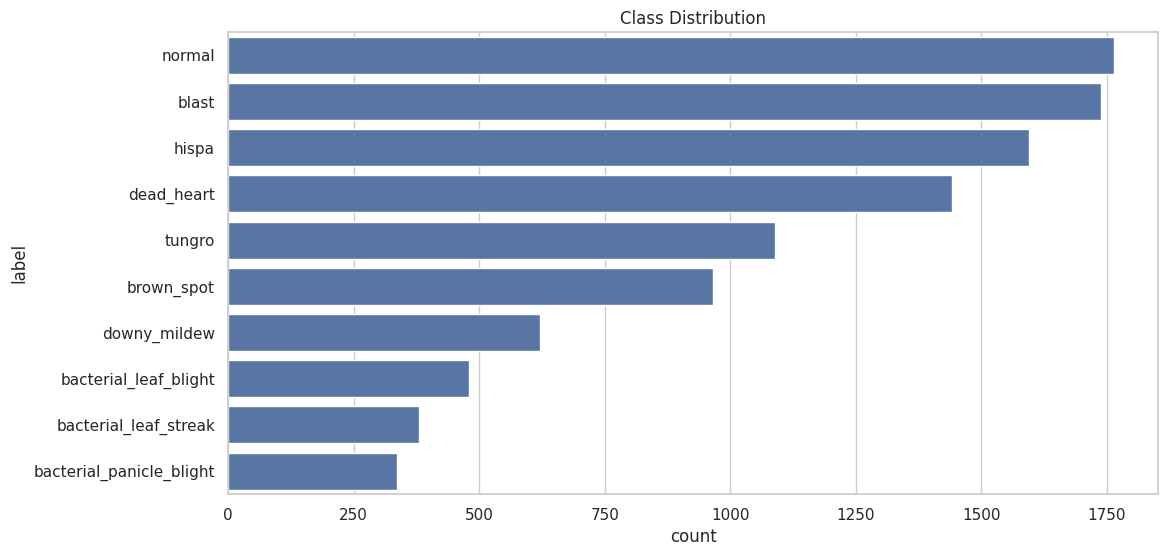

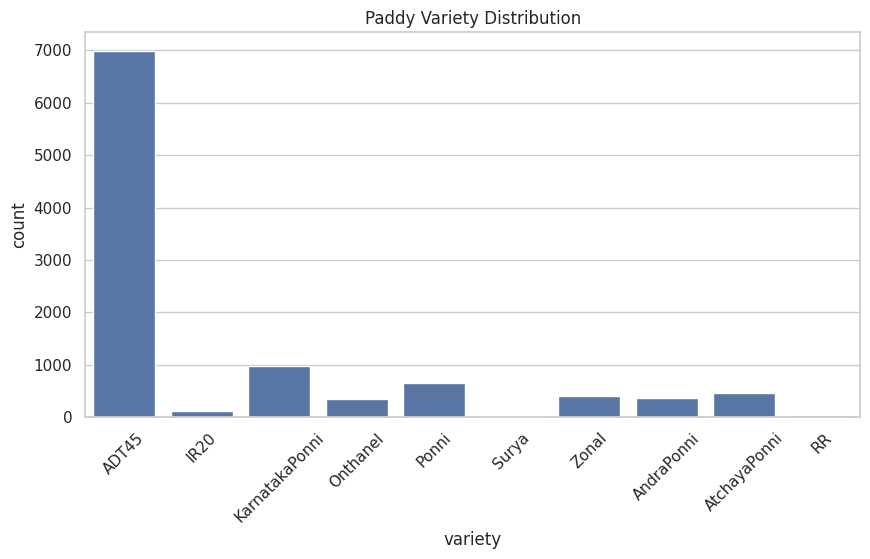

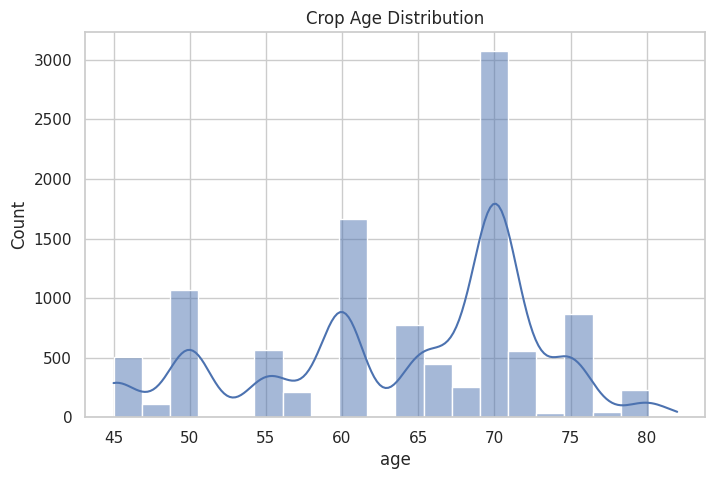

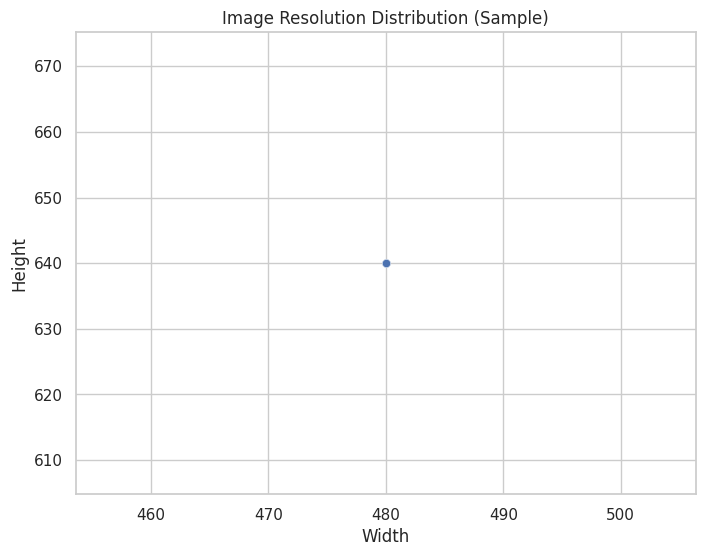

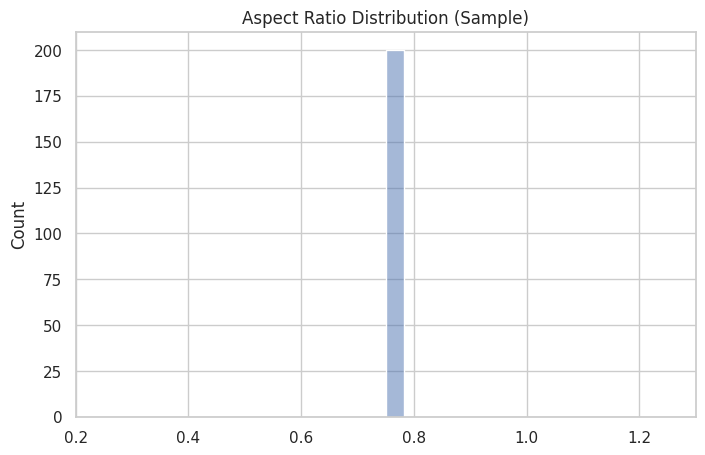

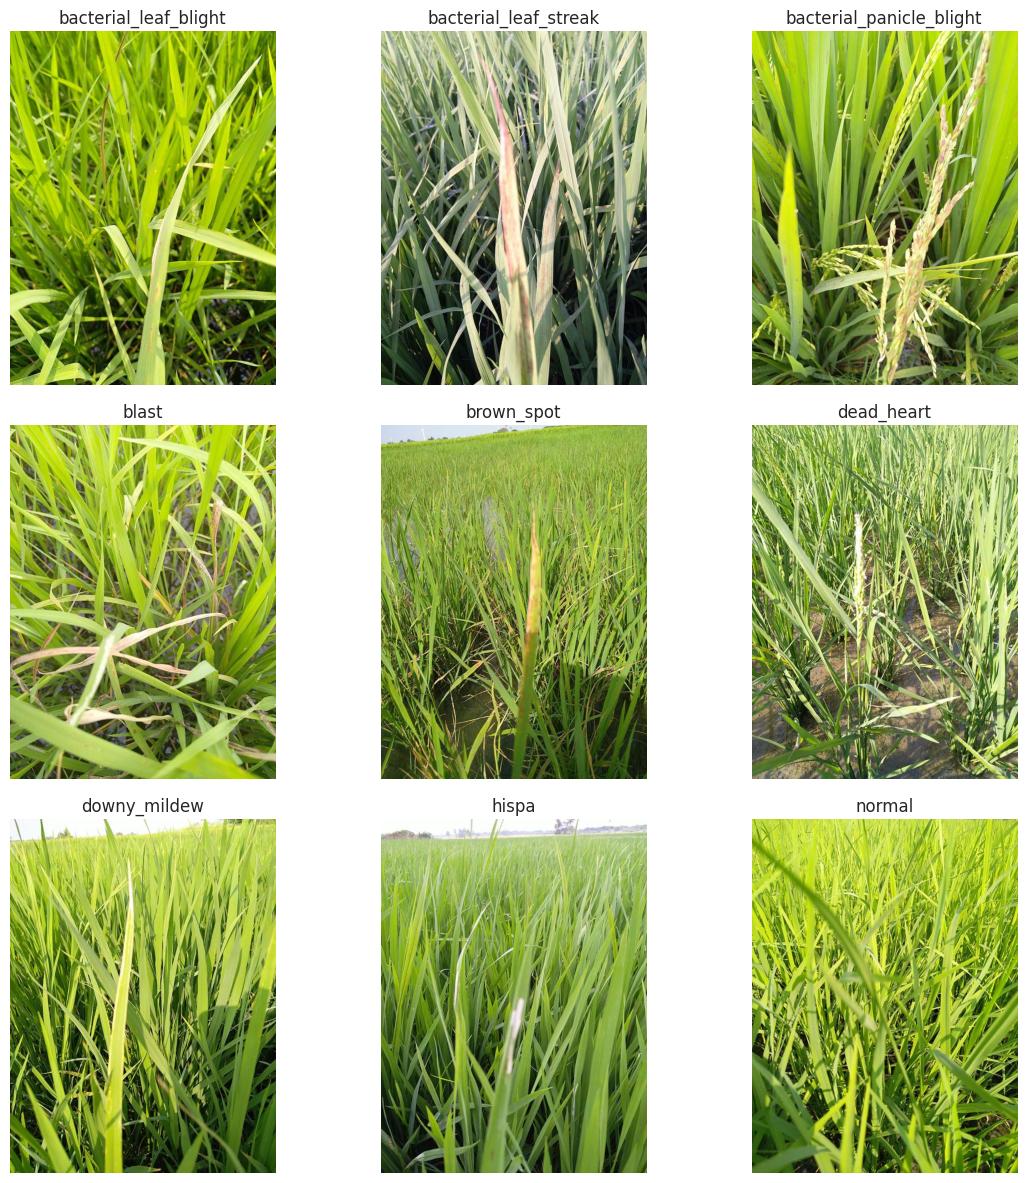

In [8]:
def perform_eda(data):
    sns.set_theme(style="whitegrid")
    
    plt.figure(figsize=(12, 6))
    sns.countplot(data=data, y='label', order=data['label'].value_counts().index)
    plt.title("Class Distribution")
    plt.savefig(os.path.join(Config.PLOT_DIR, "class_distribution.png"))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 5))
    sns.countplot(data=data, x='variety')
    plt.xticks(rotation=45)
    plt.title("Paddy Variety Distribution")
    plt.savefig(os.path.join(Config.PLOT_DIR, "variety_distribution.png"))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(8, 5))
    sns.histplot(data=data, x='age', bins=20, kde=True)
    plt.title("Crop Age Distribution")
    plt.savefig(os.path.join(Config.PLOT_DIR, "age_distribution.png"))
    plt.show()
    plt.close()

    sample_paths = data.sample(200, random_state=Config.SEED)['image_path'].values
    resolutions = []
    aspect_ratios = []
    for p in sample_paths:
        img = cv2.imread(p)
        h, w, _ = img.shape
        resolutions.append((w, h))
        aspect_ratios.append(w / h)
    
    res_df = pd.DataFrame(resolutions, columns=['Width', 'Height'])
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=res_df, x='Width', y='Height', alpha=0.5)
    plt.title("Image Resolution Distribution (Sample)")
    plt.savefig(os.path.join(Config.PLOT_DIR, "resolution_distribution.png"))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(8, 5))
    sns.histplot(aspect_ratios, bins=30, kde=True)
    plt.title("Aspect Ratio Distribution (Sample)")
    plt.savefig(os.path.join(Config.PLOT_DIR, "aspect_ratio_distribution.png"))
    plt.show()
    plt.close()
    
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    classes = data['label'].unique()
    for ax, cls in zip(axes.flatten(), classes[:9]):
        img_path = data[data['label'] == cls].iloc[0]['image_path']
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(cls)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(Config.PLOT_DIR, "image_grid.png"))
    plt.show()
    plt.close()

perform_eda(df)

In [9]:
initial_count = len(df)
df.drop_duplicates(subset=['image_id'], inplace=True)
df.dropna(subset=['label', 'variety', 'age', 'image_path'], inplace=True)
final_count = len(df)

cleaning_report = {
    "initial_samples": initial_count,
    "final_samples": final_count,
    "removed_samples": initial_count - final_count
}

with open(os.path.join(Config.OUT_DIR, "cleaning_report.json"), "w") as f:
    json.dump(cleaning_report, f, indent=4)

In [10]:
label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['label'])
variety_encoder = LabelEncoder()
df['variety_encoded'] = variety_encoder.fit_transform(df['variety'])

scaler = StandardScaler()
df['age_scaled'] = scaler.fit_transform(df[['age']])

class_names = label_encoder.classes_
num_classes = len(class_names)
num_varieties = len(variety_encoder.classes_)

train_transform = A.Compose([
    A.Resize(Config.IMG_SIZE, Config.IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.4),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.3),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

valid_transform = A.Compose([
    A.Resize(Config.IMG_SIZE, Config.IMG_SIZE),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

class PaddyDataset(Dataset):
    def __init__(self, df, transforms):
        self.df = df.reset_index(drop=True)
        self.transforms = transforms
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.cvtColor(cv2.imread(row['image_path']), cv2.COLOR_BGR2RGB)
        
        if self.transforms:
            img = self.transforms(image=img)['image']
            
        tabular = torch.tensor([row['variety_encoded'], row['age_scaled']], dtype=torch.float32)
        label = torch.tensor(row['label_encoded'], dtype=torch.long)
        
        return img, tabular, label

In [12]:
train_df, temp_df = train_test_split(
    df, test_size=0.2, stratify=df['label_encoded'], random_state=Config.SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label_encoded'], random_state=Config.SEED
)

train_dataset = PaddyDataset(train_df, train_transform)
val_dataset = PaddyDataset(val_df, valid_transform)
test_dataset = PaddyDataset(test_df, valid_transform)

class_counts = np.bincount(train_df['label_encoded'].values)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_df['label_encoded'].values]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(
    train_dataset, batch_size=Config.BATCH_SIZE, sampler=sampler,
    num_workers=Config.NUM_WORKERS, pin_memory=Config.PIN_MEMORY, drop_last=True
)

val_loader = DataLoader(
    val_dataset, batch_size=Config.BATCH_SIZE, shuffle=False,
    num_workers=Config.NUM_WORKERS, pin_memory=Config.PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset, batch_size=Config.BATCH_SIZE, shuffle=False,
    num_workers=Config.NUM_WORKERS, pin_memory=Config.PIN_MEMORY)

In [13]:
class MultiModalEfficientNet(nn.Module):
    def __init__(self, num_classes, num_varieties, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model('tf_efficientnet_b3.ns_jft_in1k', pretrained=pretrained, num_classes=0)
        num_image_features = self.backbone.num_features
        
        self.variety_embedding = nn.Embedding(num_embeddings=num_varieties, embedding_dim=16)
        self.tabular_fc = nn.Sequential(
            nn.Linear(16 + 1, 32),
            nn.BatchNorm1d(32),
            nn.SiLU(),
            nn.Dropout(0.2)
        )
        
        self.classifier = nn.Sequential(
            nn.Linear(num_image_features + 32, 512),
            nn.BatchNorm1d(512),
            nn.SiLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
        
    def forward(self, image, tabular):
        img_features = self.backbone(image)
        
        variety = tabular[:, 0].long()
        age = tabular[:, 1].unsqueeze(1)
        
        var_emb = self.variety_embedding(variety)
        tab_features = torch.cat([var_emb, age], dim=1)
        tab_features = self.tabular_fc(tab_features)
        
        combined = torch.cat([img_features, tab_features], dim=1)
        output = self.classifier(combined)
        return output

model = MultiModalEfficientNet(num_classes, num_varieties, pretrained=True).to(Config.DEVICE)

model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

In [14]:
optimizer = torch.optim.AdamW(model.parameters(), lr=Config.LEARNING_RATE, weight_decay=Config.WEIGHT_DECAY)
total_steps = len(train_loader) * Config.EPOCHS
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=total_steps//2, T_mult=1)
criterion = nn.CrossEntropyLoss()
scaler_amp = GradScaler(enabled=Config.MIXED_PRECISION)

start_epoch = 0
best_acc = 0.0
history = collections.defaultdict(list)
if 'lr' not in history:
    history['lr'] = []

last_ckpt_path = os.path.join(Config.CKPT_DIR, "last_model.pth")
if os.path.exists(last_ckpt_path):
    print("Found existing checkpoint. Resuming training...")
    checkpoint = torch.load(last_ckpt_path, map_location=Config.DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    scaler_amp.load_state_dict(checkpoint['scaler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_acc = checkpoint.get('best_acc', 0.0)
    history = checkpoint.get('history', history)
    if 'lr' not in history:
        history['lr'] = []

In [15]:
def format_time(seconds):
    m, s = divmod(int(seconds), 60)
    h, m = divmod(m, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"

for epoch in range(start_epoch, Config.EPOCHS):
    model.train()
    epoch_start_time = time.time()
    train_loss = 0.0
    
    for batch_idx, (images, tabular, labels) in enumerate(train_loader):
        batch_start_time = time.time()
        
        images = images.to(Config.DEVICE, non_blocking=True)
        tabular = tabular.to(Config.DEVICE, non_blocking=True)
        labels = labels.to(Config.DEVICE, non_blocking=True)
        
        with autocast(enabled=Config.MIXED_PRECISION):
            outputs = model(images, tabular)
            loss = criterion(outputs, labels)
            loss = loss / Config.GRAD_ACCUMULATION_STEPS
            
        scaler_amp.scale(loss).backward()
        
        if (batch_idx + 1) % Config.GRAD_ACCUMULATION_STEPS == 0:
            scaler_amp.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), Config.MAX_GRAD_NORM)
            scaler_amp.step(optimizer)
            scaler_amp.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            
        train_loss += loss.item() * Config.GRAD_ACCUMULATION_STEPS
        
        batch_time = time.time() - batch_start_time
        samples_per_sec = Config.BATCH_SIZE / batch_time
        batches_left = len(train_loader) - (batch_idx + 1)
        eta = format_time(batches_left * batch_time)
        
        # Enhanced GPU Metric Tracking
        if torch.cuda.is_available():
            gpu_mem_alloc = torch.cuda.memory_allocated() / (1024**3)
            gpu_info = f"GPU: {gpu_mem_alloc:.1f}GB"
        else:
            gpu_info = "CPU"
        
        current_lr = scheduler.get_last_lr()[0]
        
        sys.stdout.write(
            f"\rEpoch [{epoch+1}/{Config.EPOCHS}] Batch [{batch_idx+1}/{len(train_loader)}] "
            f"Loss: {loss.item()*Config.GRAD_ACCUMULATION_STEPS:.4f} LR: {current_lr:.6f} "
            f"Speed: {samples_per_sec:.1f} smp/s "
            f"{gpu_info} ETA: {eta}"
        )
        sys.stdout.flush()
        
    train_loss /= len(train_loader)
    history['lr'].append(scheduler.get_last_lr()[0])
    
    model.eval()
    val_loss = 0.0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for images, tabular, labels in val_loader:
            images = images.to(Config.DEVICE, non_blocking=True)
            tabular = tabular.to(Config.DEVICE, non_blocking=True)
            labels = labels.to(Config.DEVICE, non_blocking=True)
            
            with autocast(enabled=Config.MIXED_PRECISION):
                outputs = model(images, tabular)
                loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    val_loss /= len(val_loader)
    val_acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)
    
    epoch_time = time.time() - epoch_start_time
    
    print(f"\nEpoch {epoch+1} Summary: "
          f"Time: {format_time(epoch_time)} "
          f"Train Loss: {train_loss:.4f} "
          f"Val Loss: {val_loss:.4f} "
          f"Val Acc: {val_acc:.4f} "
          f"Best Acc: {max(best_acc, val_acc):.4f} "
          f"F1: {f1:.4f}")
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(f1)
    
    ckpt = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict': scaler_amp.state_dict(),
        'best_acc': max(best_acc, val_acc),
        'history': dict(history)
    }
    
    torch.save(ckpt, last_ckpt_path)
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(ckpt, os.path.join(Config.CKPT_DIR, "best_model.pth"))
        print(f"New best model saved with Acc: {best_acc:.4f}")

Epoch [1/5] Batch [260/260] Loss: 0.2886 LR: 0.000905 Speed: 84.4 smp/s GPU: 0.2GB ETA: 00:00:002
Epoch 1 Summary: Time: 00:02:29 Train Loss: 0.8693 Val Loss: 0.5234 Val Acc: 0.8338 Best Acc: 0.8338 F1: 0.8356
New best model saved with Acc: 0.8338
Epoch [2/5] Batch [260/260] Loss: 0.1661 LR: 0.000655 Speed: 91.3 smp/s GPU: 0.2GB ETA: 00:00:00
Epoch 2 Summary: Time: 00:01:34 Train Loss: 0.3680 Val Loss: 0.2816 Val Acc: 0.9203 Best Acc: 0.9203 F1: 0.9205
New best model saved with Acc: 0.9203
Epoch [3/5] Batch [260/260] Loss: 0.1367 LR: 0.000345 Speed: 91.6 smp/s GPU: 0.2GB ETA: 00:00:00
Epoch 3 Summary: Time: 00:01:34 Train Loss: 0.1910 Val Loss: 0.1647 Val Acc: 0.9577 Best Acc: 0.9577 F1: 0.9579
New best model saved with Acc: 0.9577
Epoch [4/5] Batch [260/260] Loss: 0.3587 LR: 0.000095 Speed: 90.5 smp/s GPU: 0.2GB ETA: 00:00:00
Epoch 4 Summary: Time: 00:01:34 Train Loss: 0.1068 Val Loss: 0.1107 Val Acc: 0.9760 Best Acc: 0.9760 F1: 0.9761
New best model saved with Acc: 0.9760
Epoch [5/5]

Loading Best Model for final evaluation...

--- Test Evaluation ---
Accuracy: 0.9673
ROC AUC:  0.9976

Classification Report:
                           precision    recall  f1-score   support

   bacterial_leaf_blight       0.96      1.00      0.98        48
   bacterial_leaf_streak       1.00      0.97      0.99        38
bacterial_panicle_blight       1.00      0.97      0.98        33
                   blast       0.97      0.97      0.97       174
              brown_spot       0.93      0.97      0.95        97
              dead_heart       1.00      0.99      1.00       144
            downy_mildew       0.93      0.87      0.90        62
                   hispa       0.96      0.96      0.96       160
                  normal       0.98      0.97      0.97       176
                  tungro       0.95      0.97      0.96       109

                accuracy                           0.97      1041
               macro avg       0.97      0.96      0.97      1041
            w

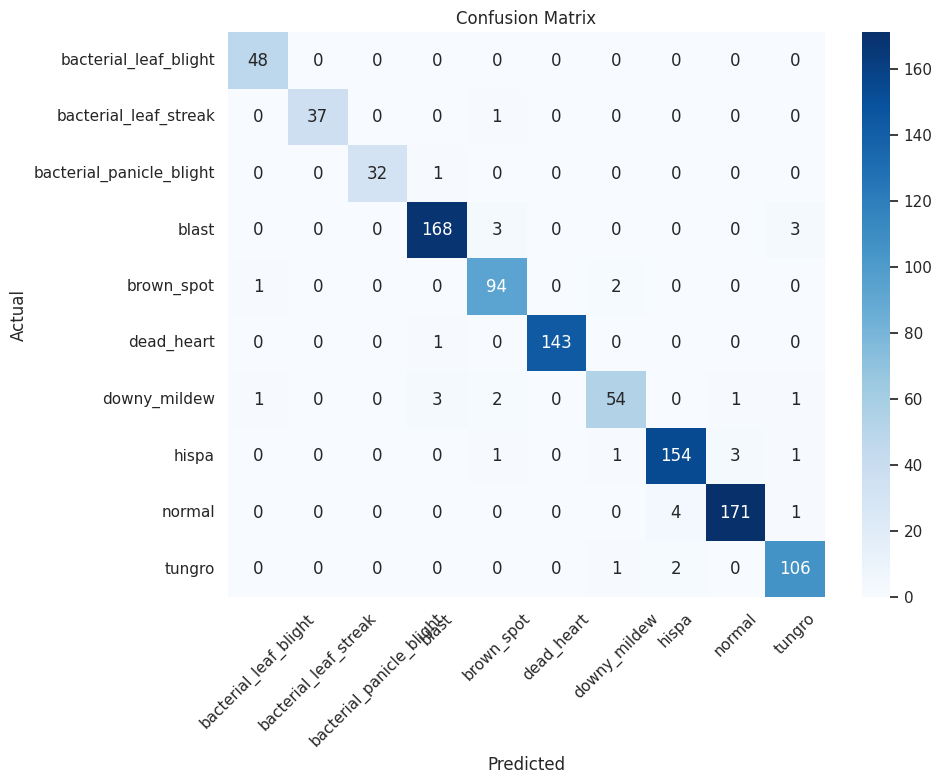

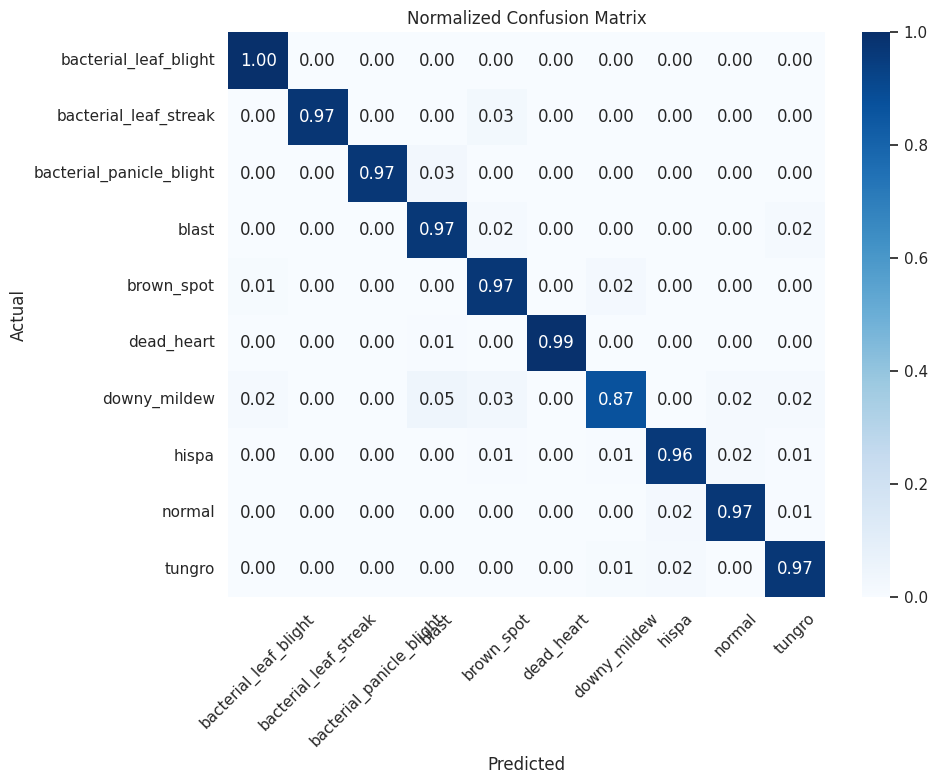

In [16]:
best_path = os.path.join(Config.CKPT_DIR, "best_model.pth")
last_path = os.path.join(Config.CKPT_DIR, "last_model.pth")

if os.path.exists(best_path):
    print("Loading Best Model for final evaluation...")
    best_ckpt = torch.load(best_path, map_location=Config.DEVICE)
    model.load_state_dict(best_ckpt['model_state_dict'])
elif os.path.exists(last_path):
    print("Best model missing. Loading Last Model for evaluation...")
    best_ckpt = torch.load(last_path, map_location=Config.DEVICE)
    model.load_state_dict(best_ckpt['model_state_dict'])
else:
    print("No checkpoints found. Proceeding with current model weights...")

model.eval()

test_preds, test_labels, test_probs = [], [], []

with torch.no_grad():
    for images, tabular, labels in test_loader:
        images = images.to(Config.DEVICE)
        tabular = tabular.to(Config.DEVICE)
        
        with autocast(enabled=Config.MIXED_PRECISION):
            outputs = model(images, tabular)
            probs = F.softmax(outputs, dim=1)
            
        preds = torch.argmax(probs, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())
        test_probs.extend(probs.cpu().numpy())

test_labels = np.array(test_labels)
test_preds = np.array(test_preds)
test_probs = np.array(test_probs)

test_acc = accuracy_score(test_labels, test_preds)
roc_auc = roc_auc_score(test_labels, test_probs, multi_class='ovr')

print("\n--- Test Evaluation ---")
print(f"Accuracy: {test_acc:.4f}")
print(f"ROC AUC:  {roc_auc:.4f}")
print("\nClassification Report:\n", classification_report(test_labels, test_preds, target_names=class_names))

cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "confusion_matrix.png"))
plt.show()
plt.close()

cm_norm = confusion_matrix(test_labels, test_preds, normalize='true')
plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Normalized Confusion Matrix')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "normalized_confusion_matrix.png"))
plt.show()

plt.close()

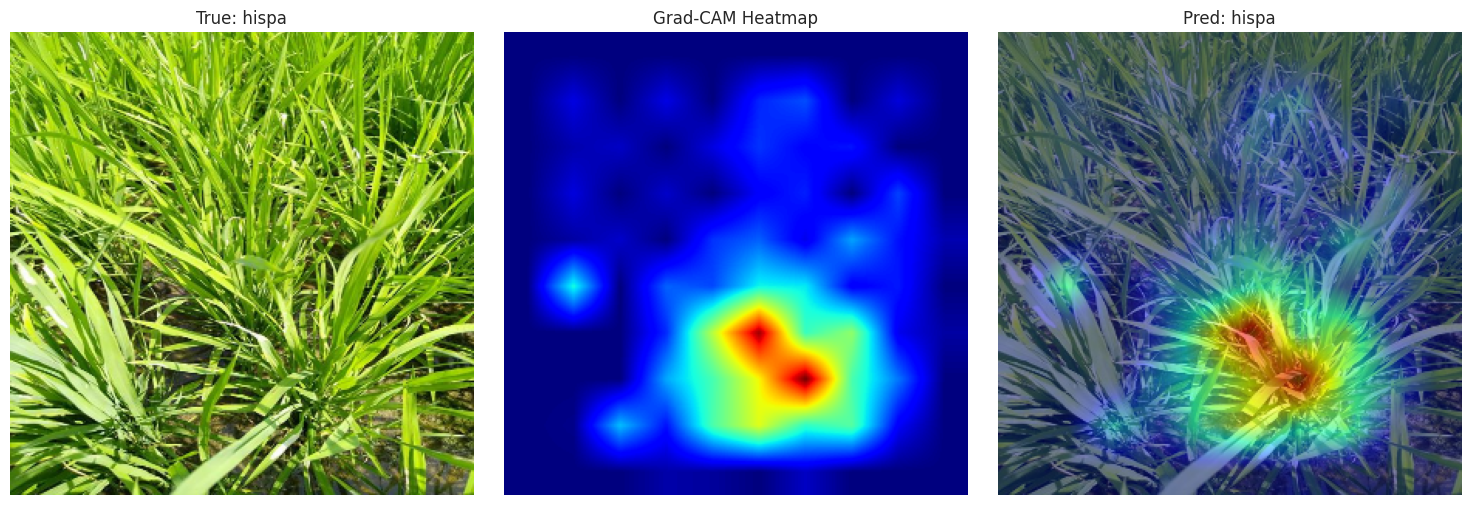

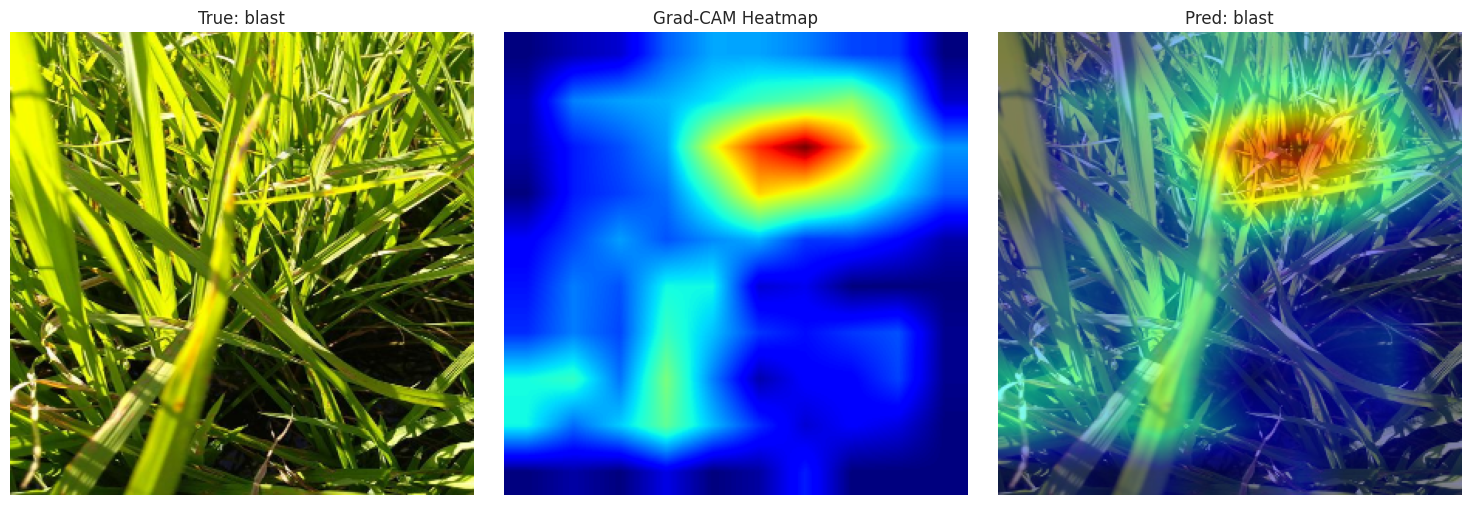

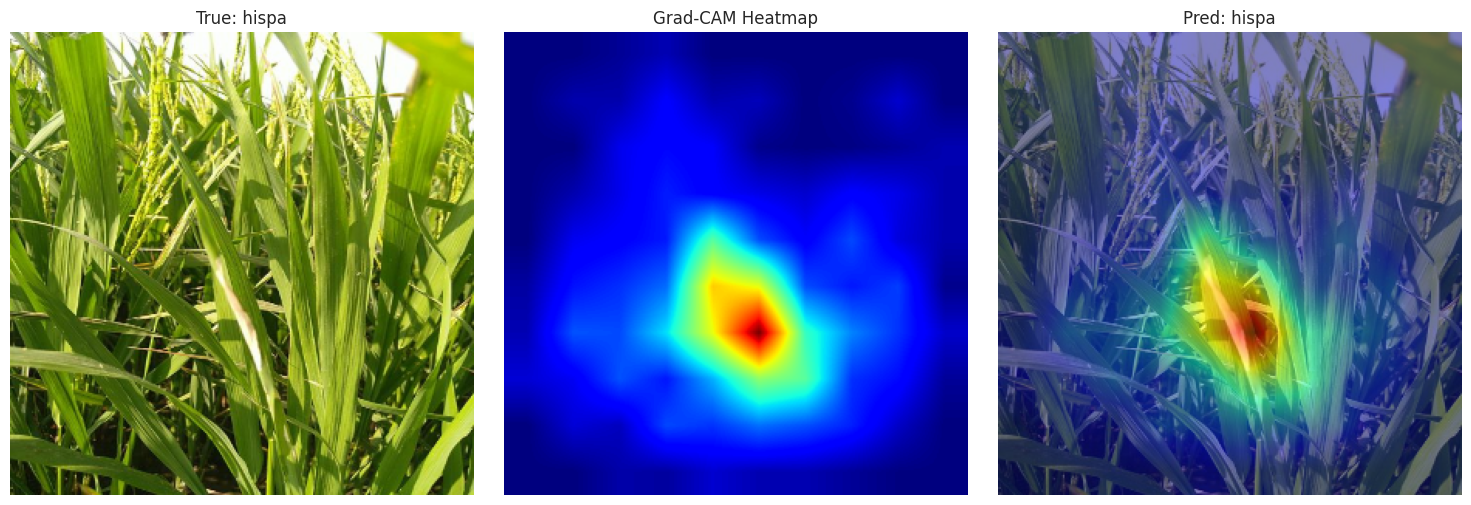

In [17]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)
        
    def save_activation(self, module, input, output):
        self.activations = output
        
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]
        
    def __call__(self, x, tabular, class_idx=None):
        b, c, h, w = x.size()
        output = self.model(x, tabular)
        
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
            
        self.model.zero_grad()
        target = output[0, class_idx]
        target.backward(retain_graph=True)
        
        gradients = self.gradients.data.cpu().numpy()[0]
        activations = self.activations.data.cpu().numpy()[0]
        
        weights = np.mean(gradients, axis=(1, 2))
        cam = np.zeros(activations.shape[1:], dtype=np.float32)
        
        for i, w_i in enumerate(weights):
            cam += w_i * activations[i]
            
        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (w, h))
        cam = cam - np.min(cam)
        cam = cam / (np.max(cam) + 1e-8)
        
        return cam, class_idx

target_layer = model.backbone.conv_head
cam_extractor = GradCAM(model, target_layer)

def generate_cam_visualization(idx, dataset, save_name):
    img_tensor, tab_tensor, true_label = dataset[idx]
    img_tensor_batch = img_tensor.unsqueeze(0).to(Config.DEVICE)
    tab_tensor_batch = tab_tensor.unsqueeze(0).to(Config.DEVICE)
    
    cam, pred_class = cam_extractor(img_tensor_batch, tab_tensor_batch)
    
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    img_np = (img_np * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    img_np = np.clip(img_np, 0, 1)
    
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    heatmap = heatmap[..., ::-1] 
    
    overlay = 0.5 * heatmap + 0.5 * img_np
    overlay = np.clip(overlay, 0, 1)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_np)
    axes[0].set_title(f"True: {class_names[true_label.item()]}")
    axes[0].axis('off')
    
    axes[1].imshow(cam, cmap='jet')
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis('off')
    
    axes[2].imshow(overlay)
    axes[2].set_title(f"Pred: {class_names[pred_class]}")
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.savefig(os.path.join(Config.PLOT_DIR, save_name))
    plt.show()
    plt.close()

model.eval()
generate_cam_visualization(0, test_dataset, "gradcam_sample_1.png")
generate_cam_visualization(1, test_dataset, "gradcam_sample_2.png")
generate_cam_visualization(2, test_dataset, "gradcam_sample_3.png")

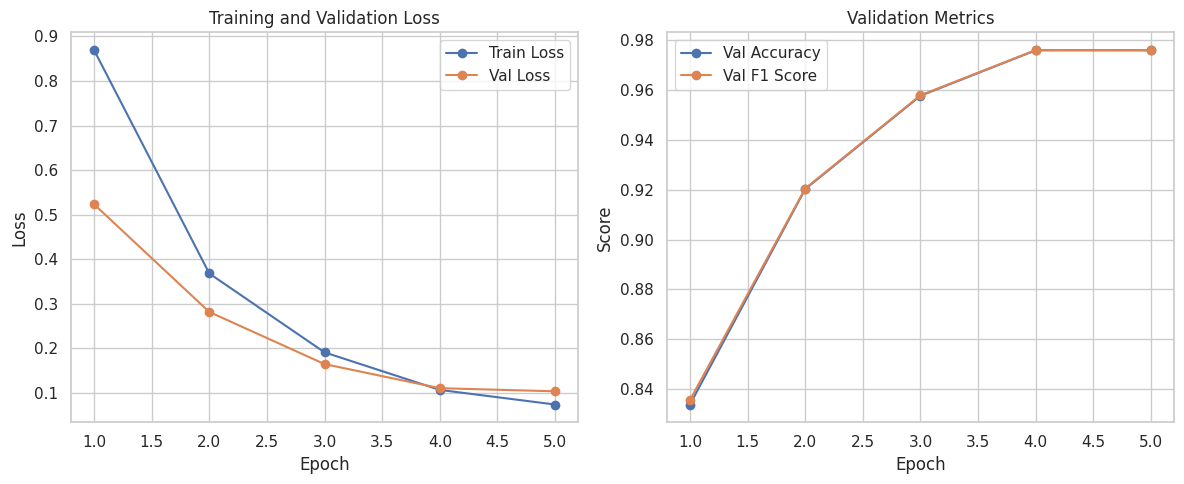

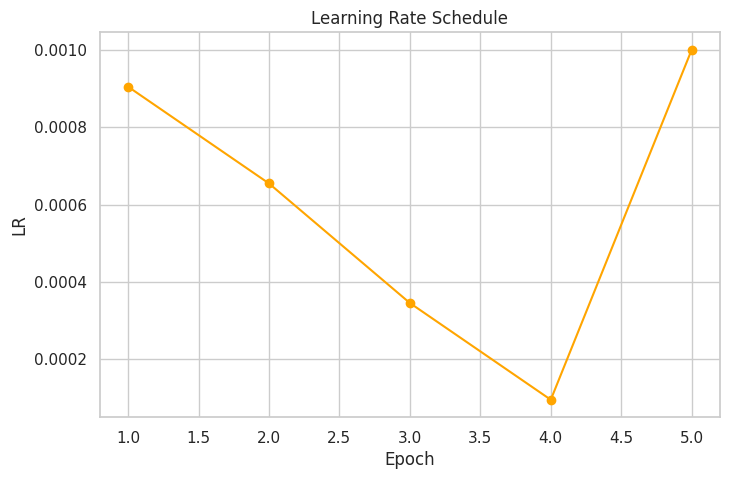

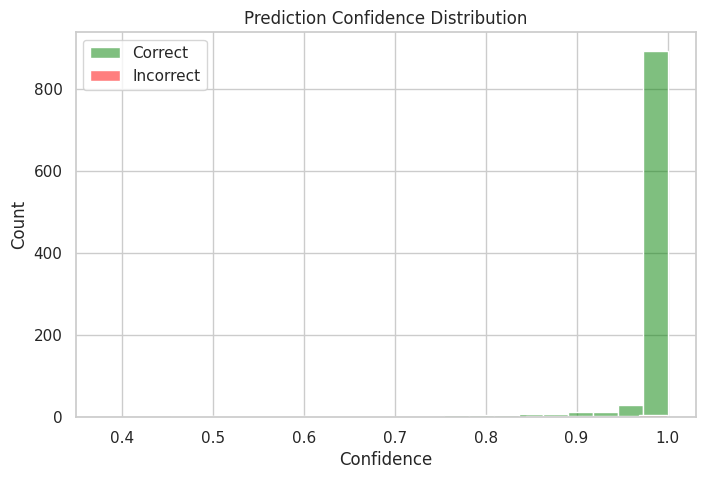

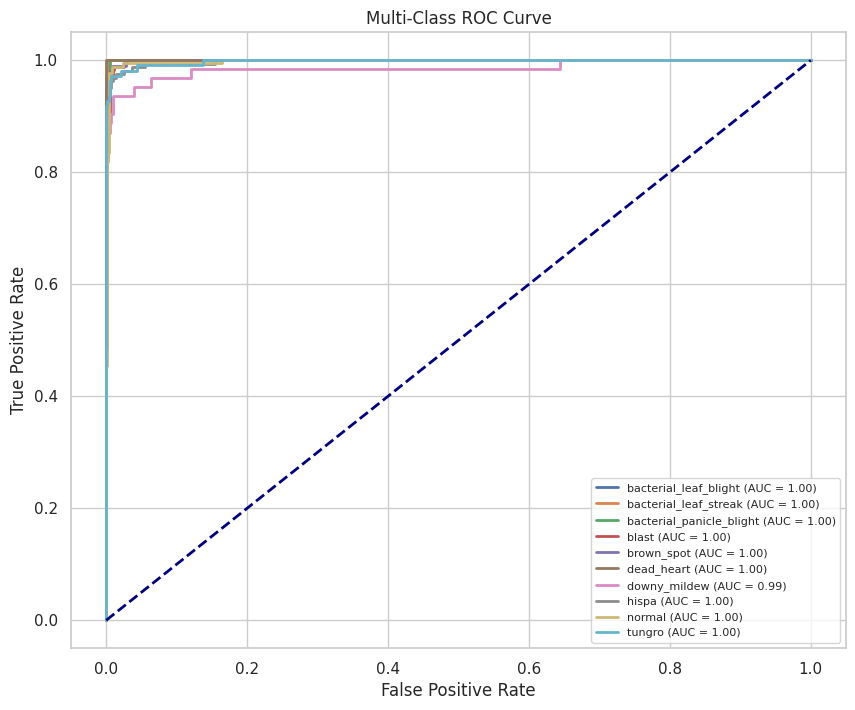

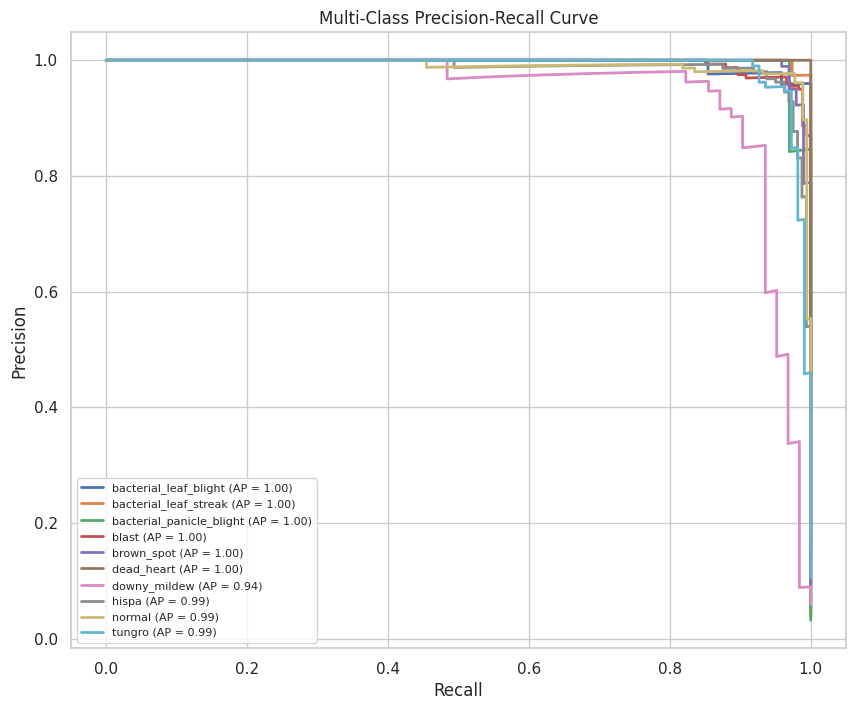

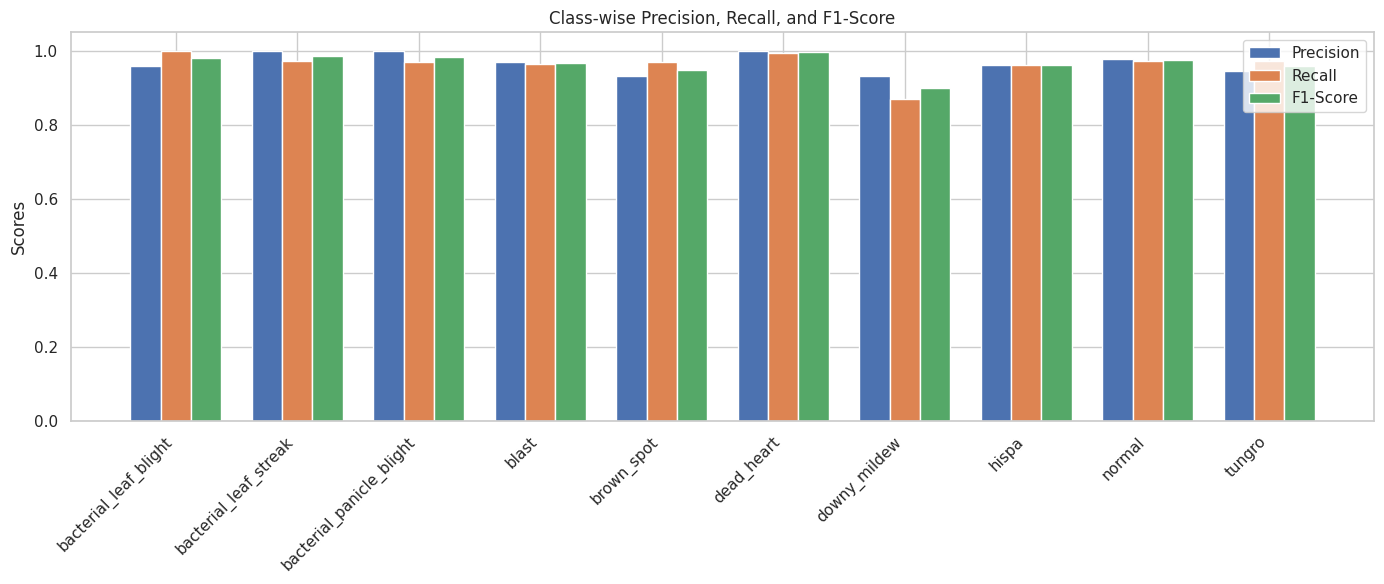

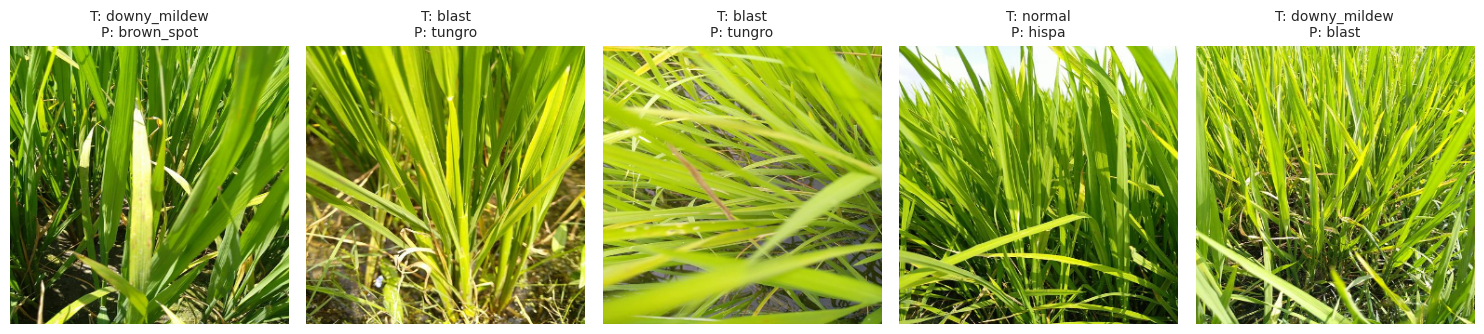

In [18]:
epochs = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, history['train_loss'], label='Train Loss', marker='o')
plt.plot(epochs, history['val_loss'], label='Val Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history['val_acc'], label='Val Accuracy', marker='o')
plt.plot(epochs, history['val_f1'], label='Val F1 Score', marker='o')
plt.title('Validation Metrics')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "training_history.png"))
plt.show()
plt.close()

if 'lr' in history and len(history['lr']) > 0:
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history['lr'], label='Learning Rate', marker='o', color='orange')
    plt.title('Learning Rate Schedule')
    plt.xlabel('Epoch')
    plt.ylabel('LR')
    plt.grid(True)
    plt.savefig(os.path.join(Config.PLOT_DIR, "learning_rate_curve.png"))
    plt.show()

    plt.close()

confidence_scores = np.max(test_probs, axis=1)
plt.figure(figsize=(8, 5))
sns.histplot(confidence_scores[test_labels == test_preds], color='green', alpha=0.5, label='Correct', bins=20)
sns.histplot(confidence_scores[test_labels != test_preds], color='red', alpha=0.5, label='Incorrect', bins=20)
plt.title("Prediction Confidence Distribution")
plt.xlabel("Confidence")
plt.legend()
plt.savefig(os.path.join(Config.PLOT_DIR, "confidence_distribution.png"))
plt.show()

plt.close()

# Multi-class ROC and PR Curves
test_labels_bin = label_binarize(test_labels, classes=range(num_classes))
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(test_labels_bin[:, i], test_probs[:, i])
    plt.plot(fpr, tpr, lw=2, label=f'{class_names[i]} (AUC = {auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curve')
plt.legend(loc="lower right", fontsize=8)
plt.savefig(os.path.join(Config.PLOT_DIR, "roc_curve.png"))
plt.show()

plt.close()

plt.figure(figsize=(10, 8))
for i in range(num_classes):
    precision_c, recall_c, _ = precision_recall_curve(test_labels_bin[:, i], test_probs[:, i])
    ap = average_precision_score(test_labels_bin[:, i], test_probs[:, i])
    plt.plot(recall_c, precision_c, lw=2, label=f'{class_names[i]} (AP = {ap:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Multi-Class Precision-Recall Curve')
plt.legend(loc="lower left", fontsize=8)
plt.savefig(os.path.join(Config.PLOT_DIR, "pr_curve.png"))
plt.show()

plt.close()

# Class-wise Metrics Bar Chart
report = classification_report(test_labels, test_preds, target_names=class_names, output_dict=True)
precisions = [report[c]['precision'] for c in class_names]
recalls = [report[c]['recall'] for c in class_names]
f1s = [report[c]['f1-score'] for c in class_names]

x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - width, precisions, width, label='Precision')
ax.bar(x, recalls, width, label='Recall')
ax.bar(x + width, f1s, width, label='F1-Score')

ax.set_ylabel('Scores')
ax.set_title('Class-wise Precision, Recall, and F1-Score')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "class_wise_metrics.png"))
plt.show()

plt.close()

# Top Misclassified Samples
misclassified_idx = np.where(test_labels != test_preds)[0]
if len(misclassified_idx) > 0:
    num_samples = min(5, len(misclassified_idx))
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 4))
    if num_samples == 1:
        axes = [axes]
    for i, idx in enumerate(misclassified_idx[:num_samples]):
        img_tensor, tab_tensor, true_label = test_dataset[idx]
        img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
        img_np = (img_np * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)
        axes[i].imshow(img_np)
        axes[i].set_title(f"T: {class_names[true_label.item()]}\nP: {class_names[test_preds[idx]]}", fontsize=10)
        axes[i].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(Config.PLOT_DIR, "top_misclassified.png"))
    plt.show()

    plt.close()

In [19]:
export_data = {
    "label_mapping": {int(k): v for k, v in enumerate(class_names)},
    "variety_mapping": {int(k): v for k, v in enumerate(variety_encoder.classes_)},
    "age_scaler_mean": scaler.mean_.tolist(),
    "age_scaler_scale": scaler.scale_.tolist(),
}

with open(os.path.join(Config.OUT_DIR, "model_metadata.json"), "w") as f:
    json.dump(export_data, f, indent=4)

history_df = pd.DataFrame(history)
history_df.to_csv(os.path.join(Config.OUT_DIR, "training_history.csv"), index=False)

# Saving extensive final metrics to JSON and CSV
best_epoch_val = int(best_ckpt['epoch'] + 1) if 'best_ckpt' in locals() and 'epoch' in best_ckpt else int(epoch + 1)
final_metrics = {
    "Model Name": "MultiModalEfficientNet-B3",
    "Best Epoch": best_epoch_val,
    "Best Accuracy": float(best_acc),
    "Test Accuracy": float(test_acc),
    "Test Precision": float(precision_score(test_labels, test_preds, average='weighted', zero_division=0)),
    "Test Recall": float(recall_score(test_labels, test_preds, average='weighted', zero_division=0)),
    "Test F1 Score": float(f1_score(test_labels, test_preds, average='weighted', zero_division=0)),
    "Test ROC AUC": float(roc_auc),
    "Total Training Epochs": int(epoch + 1),
    "Batch Size": Config.BATCH_SIZE,
    "Image Size": Config.IMG_SIZE,
    "Learning Rate": Config.LEARNING_RATE,
    "Total Records Processed": len(df)
}

with open(os.path.join(Config.OUT_DIR, "final_metrics.json"), "w") as f:
    json.dump(final_metrics, f, indent=4)
    
pd.DataFrame([final_metrics]).to_csv(os.path.join(Config.OUT_DIR, "final_metrics.csv"), index=False)

print(f"\nAll artifacts saved to {Config.OUT_DIR}")


All artifacts saved to ./output


DATASET SUMMARY
Total samples: 8325
Number of classes: 10
label
normal                      1411
blast                       1390
hispa                       1275
dead_heart                  1154
tungro                       870
brown_spot                   772
downy_mildew                 496
bacterial_leaf_blight        383
bacterial_leaf_streak        304
bacterial_panicle_blight     270
Name: count, dtype: int64
Missing values:
image_id           0
label              0
variety            0
age                0
image_path         0
label_encoded      0
variety_encoded    0
age_scaled         0
dtype: int64


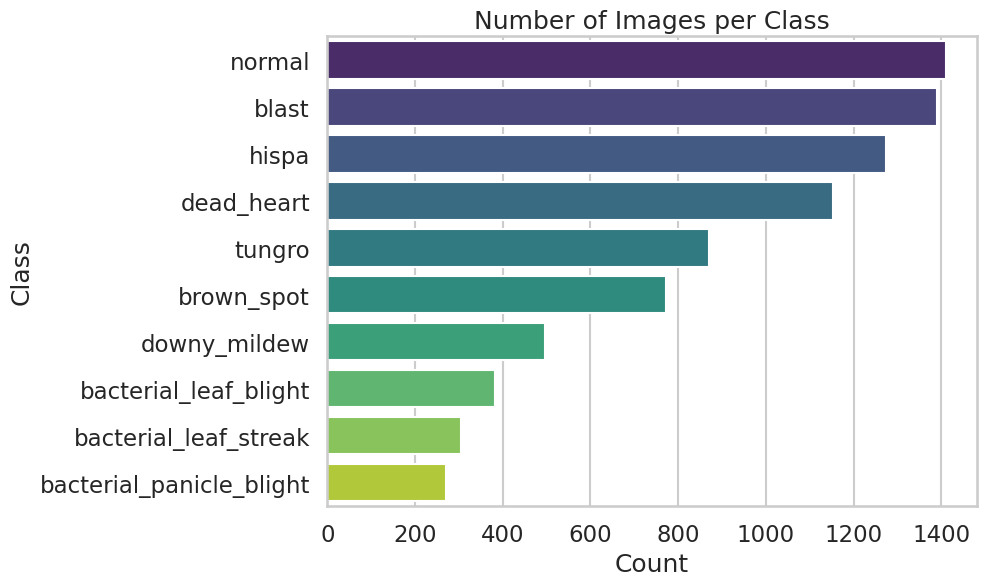

✓ Figure saved: output/plots/01_class_distribution_bar.png


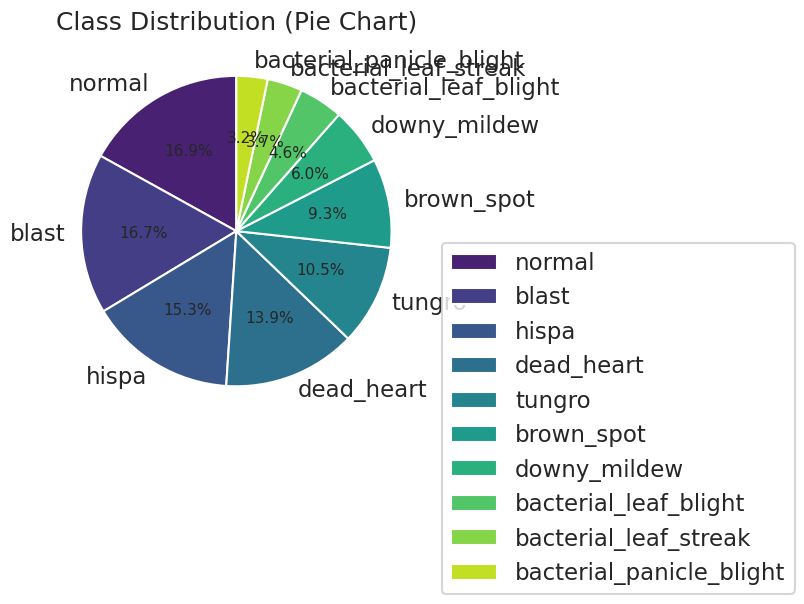

✓ Figure saved: output/plots/02_class_distribution_pie.png
No missing values found.
 Skipped [Sample Images per Class]: expected str, bytes or os.PathLike object, not NoneType
 Skipped [Image Resolution / Width / Height / Aspect Ratio Distributions]: expected str, bytes or os.PathLike object, not NoneType
PREPROCESSING VISUALIZATIONS


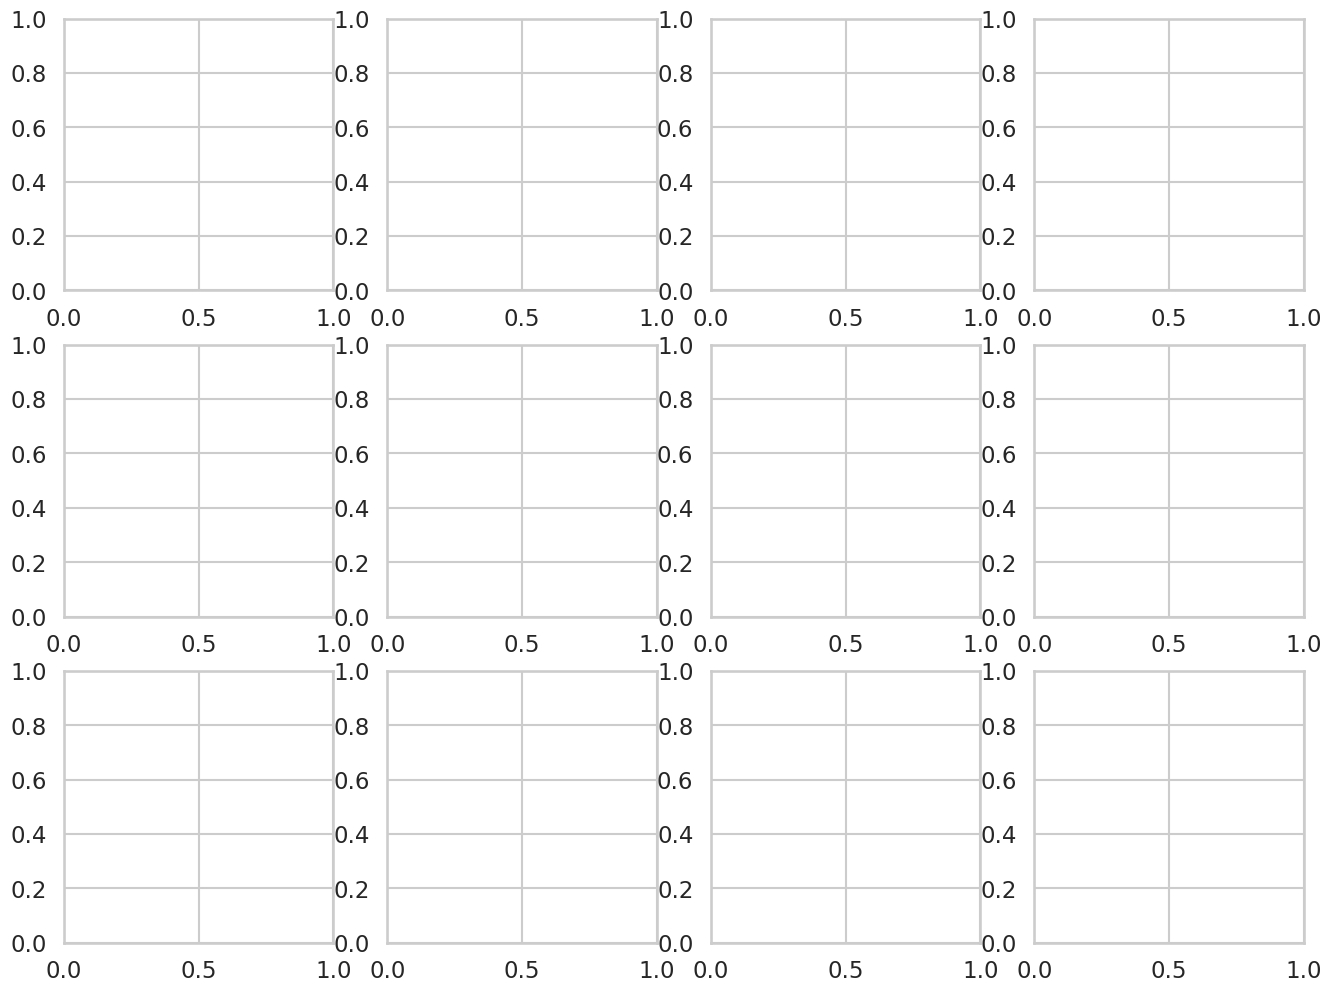

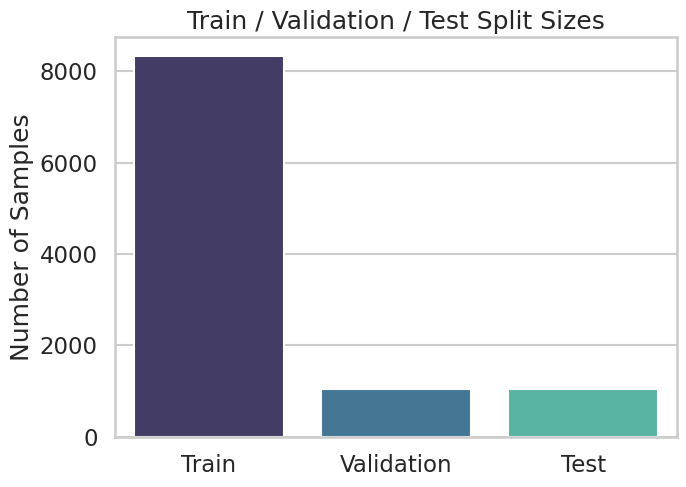

✓ Figure saved: output/plots/06_split_distribution.png
 Skipped [Before vs After Preprocessing]: expected str, bytes or os.PathLike object, not NoneType
 Skipped [Original vs Augmented Comparison]: expected str, bytes or os.PathLike object, not NoneType
 Skipped [Normalization Visualization]: expected str, bytes or os.PathLike object, not NoneType
Train dataset size: 8325
Validation dataset size: 1041
Test dataset size: 1041
Dataset verification complete.
TRAINING VISUALIZATIONS


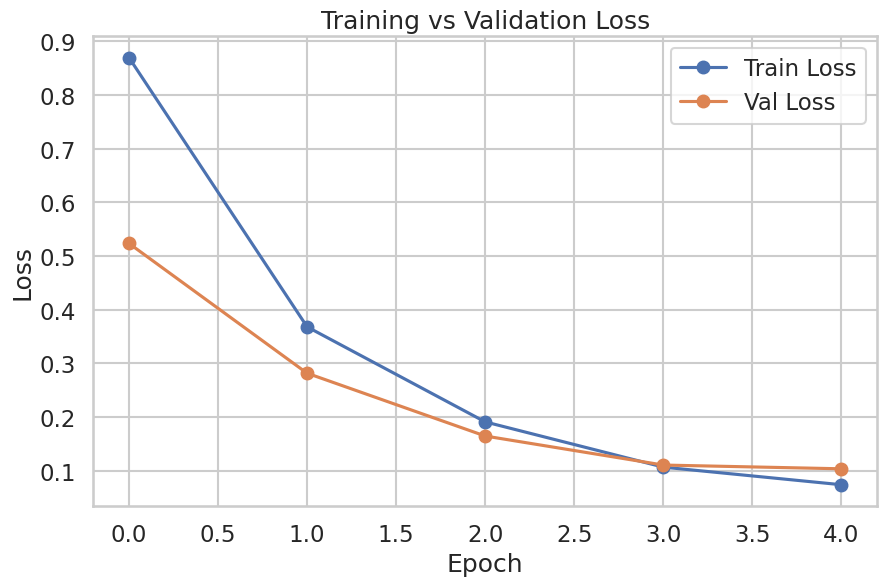

✓ Figure saved: output/plots/10_loss_curves.png


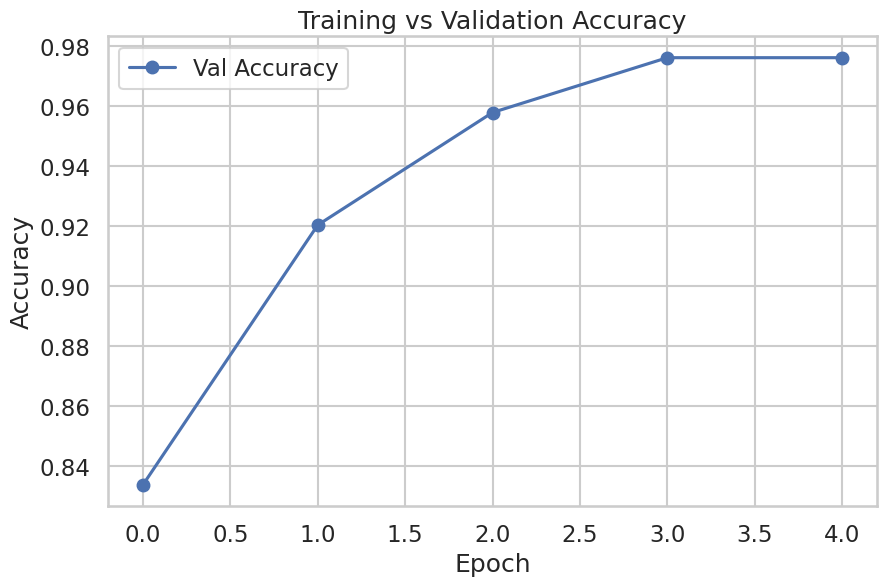

✓ Figure saved: output/plots/11_accuracy_curves.png


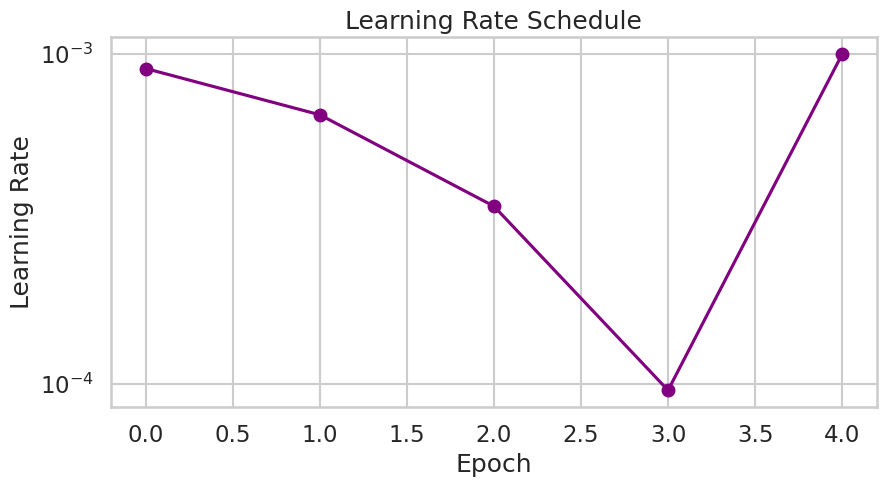

✓ Figure saved: output/plots/12_lr_schedule.png


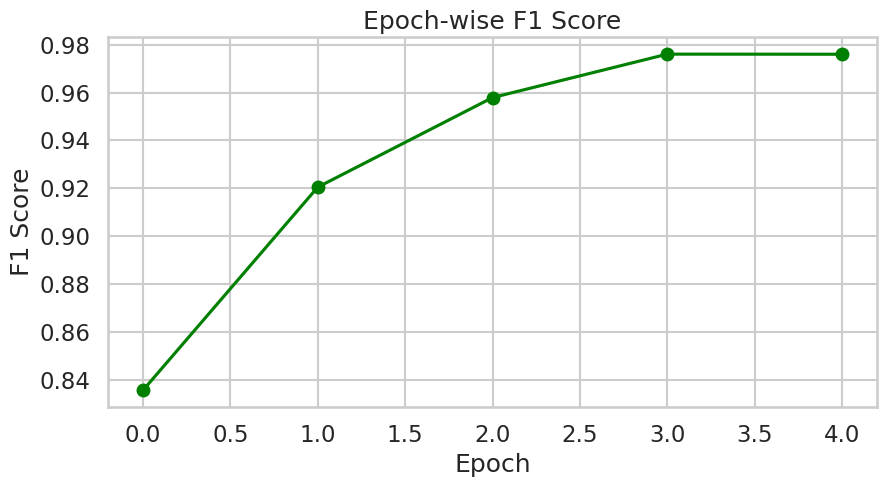

✓ Figure saved: output/plots/13_epoch_f1.png
MODEL EVALUATION


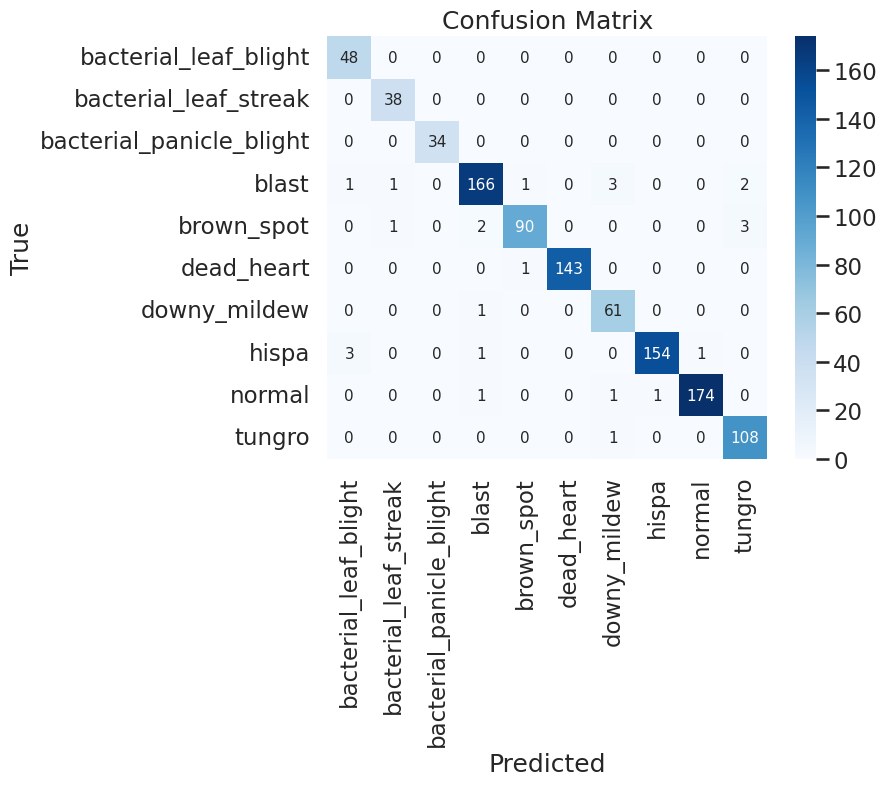

✓ Figure saved: output/plots/14_confusion_matrix.png


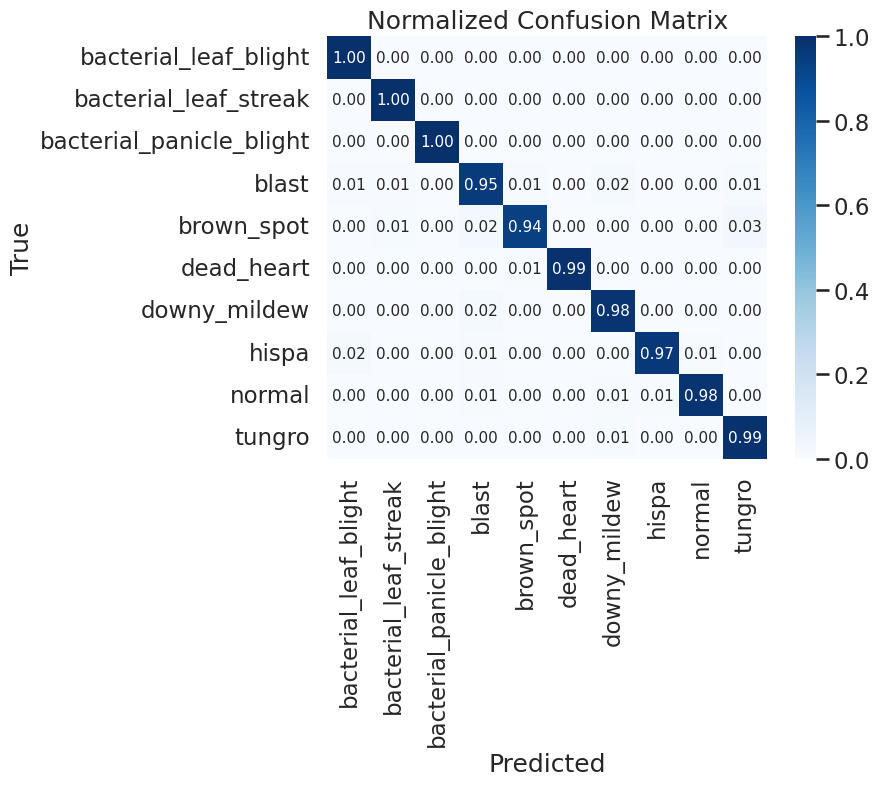

✓ Figure saved: output/plots/15_confusion_matrix_normalized.png


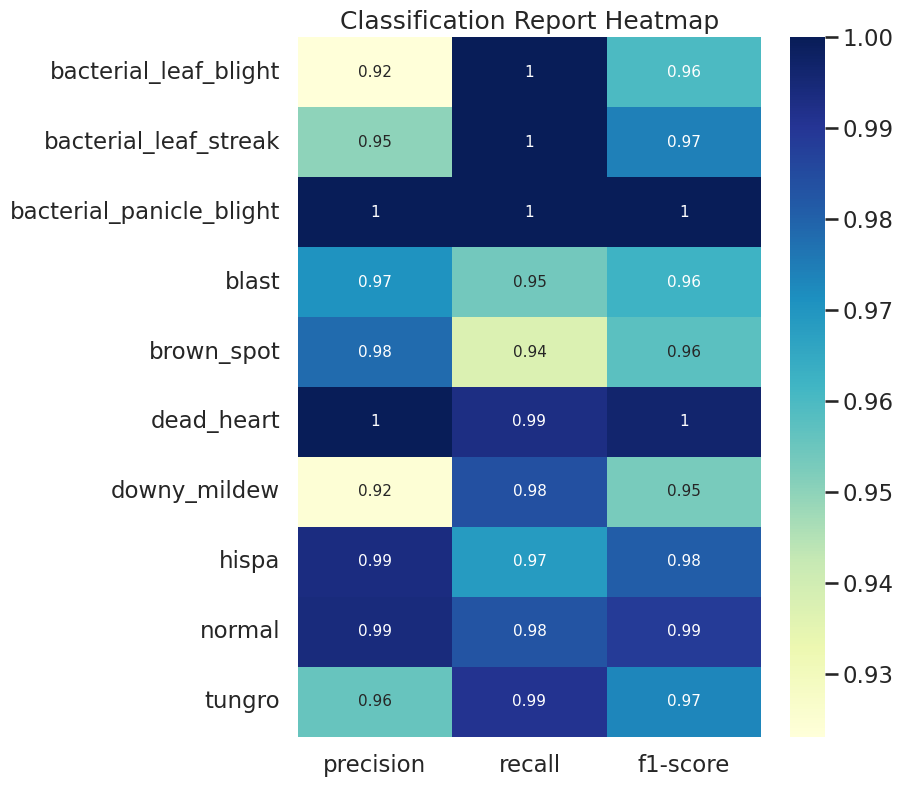

✓ Figure saved: output/plots/16_classification_report_heatmap.png


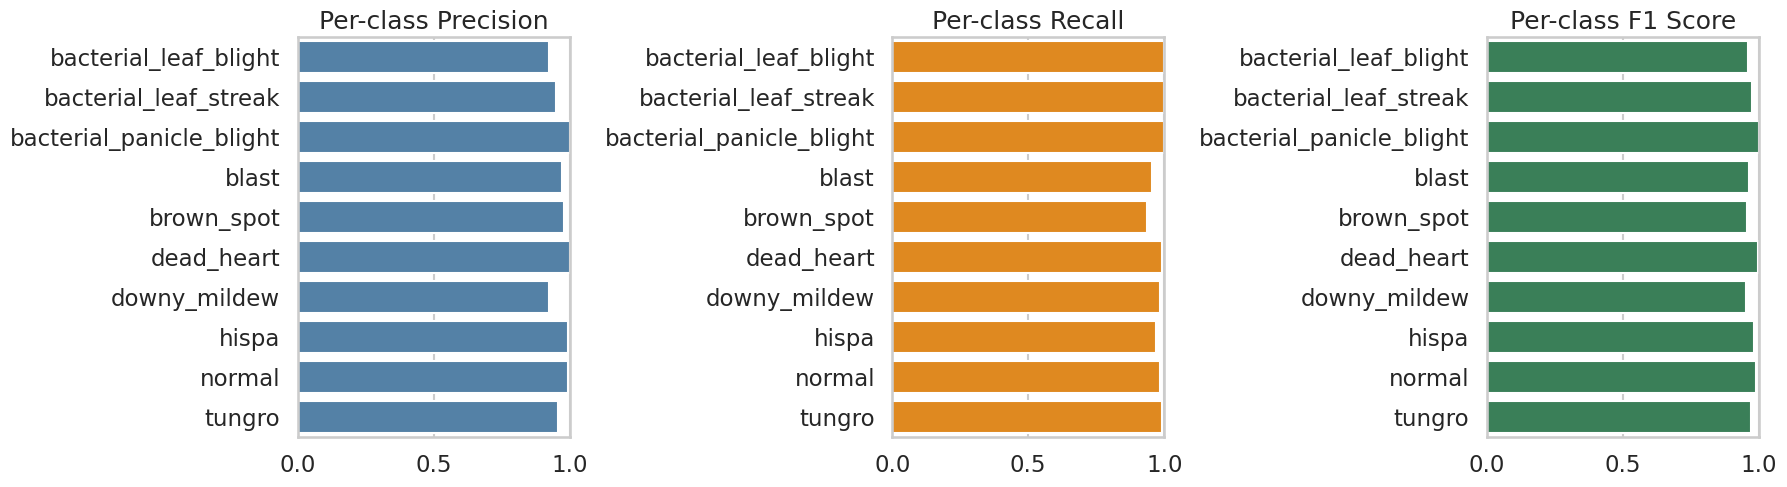

✓ Figure saved: output/plots/17_per_class_precision_recall_f1.png
 Skipped [Prediction Confidence Histogram]: max() received an invalid combination of arguments - got (out=NoneType, axis=int, ), but expected one of:
 * ()
 * (Tensor other)
 * (int dim, bool keepdim = False)
      didn't match because some of the keywords were incorrect: out, axis
 * (name dim, bool keepdim = False)
      didn't match because some of the keywords were incorrect: out, axis

 Skipped [ROC Curve (One-vs-Rest)]: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.
 Skipped [Precision-Recall Curves]: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.
ERROR ANALYSIS
 Skipped [Top Correct / Misclassified / High-Confidence-Wrong / Low-Confidence-Correct]: max() received an invalid combination of arguments - got (out=NoneType, axis=int, ), but expected one of:
 * ()
 * (Tensor other)
 * (int dim, bool 

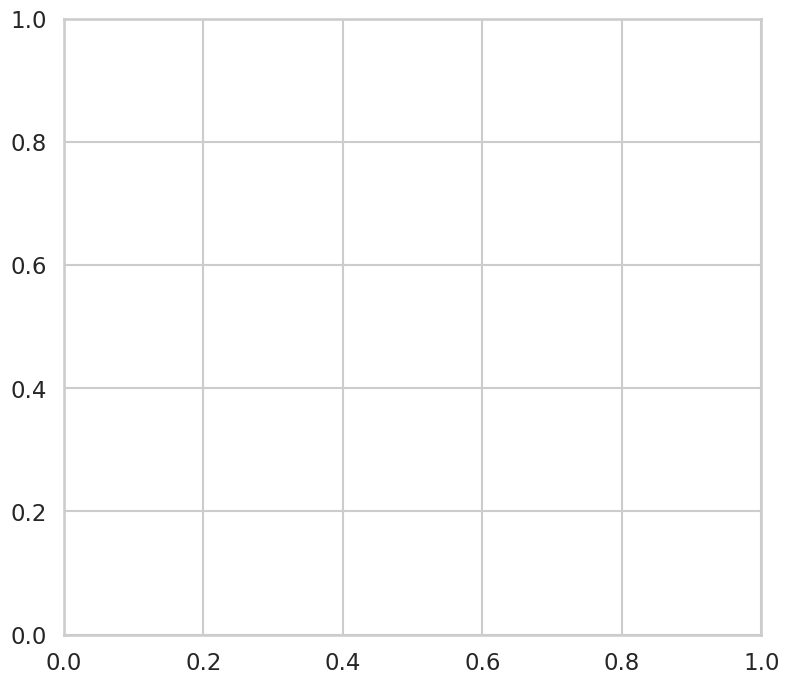

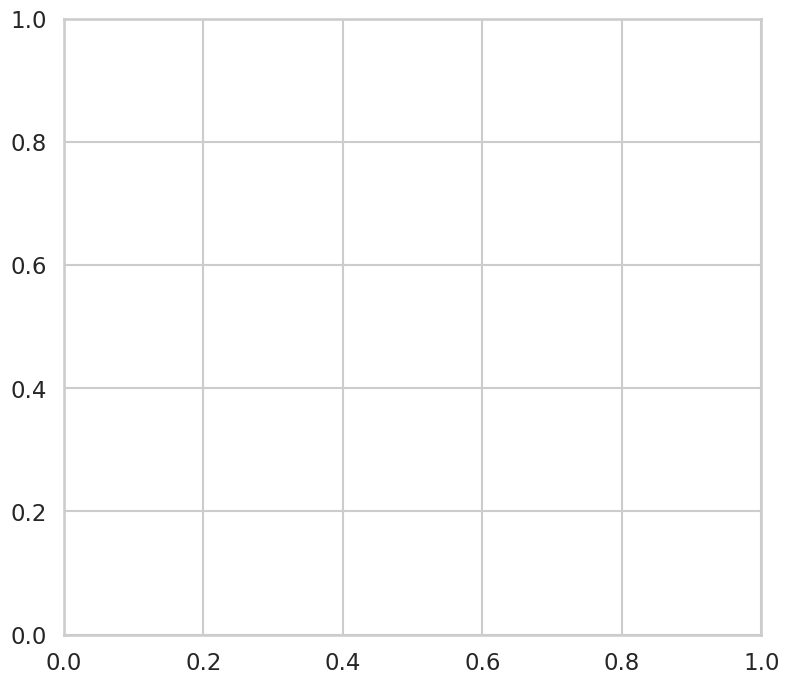

In [21]:
import os, math, itertools, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11

OUT_DIR = "output"
PLOT_DIR = os.path.join(OUT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

def _g(*names):
    for n in names:
        if n in globals():
            return globals()[n]
    return None

def save_fig(fig, name):
    try:
        fig.tight_layout()
        plt.show()
        path = os.path.join(PLOT_DIR, f"{name}.png")
        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.close(fig)
        print(f"✓ Figure saved: {path}")
    except Exception as e:
        print(f"✗ Could not save {name}: {e}")
        try:
            plt.close(fig)
        except Exception:
            pass

def safe_block(title):
    def deco(fn):
        def wrapper(*args, **kwargs):
            try:
                return fn(*args, **kwargs)
            except Exception as e:
                print(f" Skipped [{title}]: {e}")
        return wrapper
    return deco

# ---- Resolve common variable names from the notebook ----
train_df       = _g("train_df", "df", "dataframe", "labels_df")
class_names    = _g("class_names", "classes", "CLASSES", "label_names")
train_dir      = _g("train_dir", "TRAIN_DIR", "data_dir", "DATA_DIR", "image_dir")
history        = _g("history", "History", "train_history", "hist")
y_true         = _g("y_true", "true_labels", "val_labels", "targets", "all_labels")
y_pred         = _g("y_pred", "pred_labels", "predictions", "all_preds")
y_prob         = _g("y_prob", "y_probs", "probs", "all_probs", "prediction_probs")
train_ds       = _g("train_dataset", "train_ds", "train_data")
val_ds         = _g("val_dataset", "val_ds", "valid_dataset", "val_data")
test_ds        = _g("test_dataset", "test_ds", "test_data")
gradcam_imgs   = _g("gradcam_images", "cam_images", "grad_cam_outputs")
orig_imgs_for_cam = _g("gradcam_originals", "cam_originals")
mean_norm      = _g("MEAN", "mean", "IMG_MEAN", "normalize_mean")
std_norm       = _g("STD", "std", "IMG_STD", "normalize_std")
label_col      = _g("label_col", "LABEL_COL") or "label"
image_col      = _g("image_col", "IMAGE_COL") or "image_id"

print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

@safe_block("Dataset Summary")
def _s1():
    if train_df is not None:
        print(f"Total samples: {len(train_df)}")
        if label_col in train_df.columns:
            print(f"Number of classes: {train_df[label_col].nunique()}")
            print(train_df[label_col].value_counts())
        print(f"Missing values:\n{train_df.isnull().sum()}")
    else:
        print("train_df not found, skipping summary.")
_s1()

@safe_block("Class Distribution Bar Chart")
def _s2():
    counts = train_df[label_col].value_counts()
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(x=counts.values, y=counts.index, ax=ax, palette="viridis")
    ax.set_title("Number of Images per Class")
    ax.set_xlabel("Count")
    ax.set_ylabel("Class")
    save_fig(fig, "01_class_distribution_bar")
_s2()

@safe_block("Class Distribution Pie Chart")
def _s3():
    counts = train_df[label_col].value_counts()
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette("viridis", len(counts)))
    ax.set_title("Class Distribution (Pie Chart)")
    ax.legend(counts.index, loc="best", bbox_to_anchor=(1, 0.5))
    save_fig(fig, "02_class_distribution_pie")
_s3()

@safe_block("Missing Value Summary")
def _s4():
    miss = train_df.isnull().sum()
    miss = miss[miss > 0]
    if len(miss) == 0:
        print("No missing values found.")
        return
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(x=miss.values, y=miss.index, ax=ax, color="salmon")
    ax.set_title("Missing Values per Column")
    save_fig(fig, "03_missing_values")
_s4()

@safe_block("Sample Images per Class")
def _s5():
    import cv2
    classes_ = class_names if class_names is not None else train_df[label_col].unique().tolist()
    n = len(classes_)
    cols = min(4, n)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)
    for i, cls in enumerate(classes_):
        row = train_df[train_df[label_col] == cls].iloc[0]
        img_path = os.path.join(train_dir, str(row[image_col]))
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[i].imshow(img)
        axes[i].set_title(str(cls))
        axes[i].axis("off")
    for j in range(len(classes_), len(axes)):
        axes[j].axis("off")
    fig.suptitle("Sample Images per Class")
    save_fig(fig, "04_sample_images_per_class")
_s5()

@safe_block("Image Resolution / Width / Height / Aspect Ratio Distributions")
def _s6():
    import cv2
    widths, heights = [], []
    sample_df = train_df.sample(min(300, len(train_df)), random_state=42)
    for _, row in sample_df.iterrows():
        img_path = os.path.join(train_dir, str(row[image_col]))
        img = cv2.imread(img_path)
        if img is None:
            continue
        h, w = img.shape[:2]
        widths.append(w)
        heights.append(h)
    widths, heights = np.array(widths), np.array(heights)
    aspect = widths / heights

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    sns.histplot(widths, kde=True, ax=axes[0, 0], color="steelblue")
    axes[0, 0].set_title("Image Width Distribution")
    sns.histplot(heights, kde=True, ax=axes[0, 1], color="darkorange")
    axes[0, 1].set_title("Image Height Distribution")
    sns.scatterplot(x=widths, y=heights, ax=axes[1, 0], alpha=0.5)
    axes[1, 0].set_title("Image Resolution Distribution (W vs H)")
    sns.histplot(aspect, kde=True, ax=axes[1, 1], color="seagreen")
    axes[1, 1].set_title("Aspect Ratio Distribution")
    save_fig(fig, "05_resolution_width_height_aspect")
_s6()

print("=" * 60)
print("PREPROCESSING VISUALIZATIONS")
print("=" * 60)

@safe_block("Train/Val/Test Split Distribution")
def _p1():
    sizes, labels_ = [], []
    for name, ds in [("Train", train_ds), ("Validation", val_ds), ("Test", test_ds)]:
        if ds is not None:
            try:
                sizes.append(len(ds))
            except Exception:
                continue
            labels_.append(name)
    if not sizes:
        raise ValueError("no split datasets found")
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.barplot(x=labels_, y=sizes, ax=ax, palette="mako")
    ax.set_title("Train / Validation / Test Split Sizes")
    ax.set_ylabel("Number of Samples")
    save_fig(fig, "06_split_distribution")
_p1()

@safe_block("Before vs After Preprocessing")
def _p2():
    import cv2
    row = train_df.iloc[0]
    img_path = os.path.join(train_dir, str(row[image_col]))
    orig = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    img_size = _g("IMG_SIZE", "IMAGE_SIZE", "img_size") or 300
    if isinstance(img_size, (tuple, list)):
        img_size = img_size[0]
    processed = cv2.resize(orig, (img_size, img_size))

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(orig); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(processed); axes[1].set_title("Preprocessed (Resized)"); axes[1].axis("off")
    fig.suptitle("Before vs After Preprocessing")
    save_fig(fig, "07_before_after_preprocessing")
_p2()

@safe_block("Original vs Augmented Comparison")
def _p3():
    train_transform = _g("train_transform", "train_transforms", "augmentations", "train_tfms")
    import cv2
    row = train_df.iloc[0]
    img_path = os.path.join(train_dir, str(row[image_col]))
    orig = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(orig); axes[0].set_title("Original"); axes[0].axis("off")
    for i in range(1, 4):
        try:
            augmented = train_transform(image=orig)["image"] if train_transform else train_transform(orig)
        except Exception:
            augmented = train_transform(orig)
        aug_np = augmented
        if hasattr(aug_np, "numpy"):
            aug_np = aug_np.permute(1, 2, 0).numpy() if aug_np.shape[0] in (1, 3) else aug_np.numpy()
            aug_np = (aug_np - aug_np.min()) / (aug_np.max() - aug_np.min() + 1e-8)
        axes[i].imshow(aug_np)
        axes[i].set_title(f"Augmented {i}")
        axes[i].axis("off")
    fig.suptitle("Original vs Augmented Samples")
    save_fig(fig, "08_original_vs_augmented")
_p3()

@safe_block("Normalization Visualization")
def _p4():
    import cv2
    row = train_df.iloc[0]
    img_path = os.path.join(train_dir, str(row[image_col]))
    orig = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    mean = np.array(mean_norm) if mean_norm is not None else np.array([0.485, 0.456, 0.406])
    std = np.array(std_norm) if std_norm is not None else np.array([0.229, 0.224, 0.225])
    normalized = (orig - mean) / std
    display_norm = (normalized - normalized.min()) / (normalized.max() - normalized.min() + 1e-8)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(orig); axes[0].set_title("Original (0-1 scaled)"); axes[0].axis("off")
    axes[1].imshow(display_norm); axes[1].set_title("Normalized (rescaled for display)"); axes[1].axis("off")
    fig.suptitle("Normalization Visualization")
    save_fig(fig, "09_normalization")
_p4()

@safe_block("Dataset Verification Summary")
def _p5():
    print(f"Train dataset size: {len(train_ds) if train_ds is not None else 'N/A'}")
    print(f"Validation dataset size: {len(val_ds) if val_ds is not None else 'N/A'}")
    print(f"Test dataset size: {len(test_ds) if test_ds is not None else 'N/A'}")
    print("Dataset verification complete.")
_p5()

print("=" * 60)
print("TRAINING VISUALIZATIONS")
print("=" * 60)

def _get_hist_key(*keys):
    if history is None:
        return None
    h = history.history if hasattr(history, "history") else history
    for k in keys:
        if isinstance(h, dict) and k in h:
            return h[k]
    return None

@safe_block("Training/Validation Loss")
def _t1():
    train_loss = _get_hist_key("loss", "train_loss", "training_loss")
    val_loss = _get_hist_key("val_loss", "validation_loss")
    fig, ax = plt.subplots(figsize=(9, 6))
    if train_loss: ax.plot(train_loss, label="Train Loss", marker="o")
    if val_loss: ax.plot(val_loss, label="Val Loss", marker="o")
    ax.set_title("Training vs Validation Loss")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.legend()
    save_fig(fig, "10_loss_curves")
_t1()

@safe_block("Training/Validation Accuracy")
def _t2():
    train_acc = _get_hist_key("accuracy", "acc", "train_acc", "training_accuracy")
    val_acc = _get_hist_key("val_accuracy", "val_acc", "validation_accuracy")
    fig, ax = plt.subplots(figsize=(9, 6))
    if train_acc: ax.plot(train_acc, label="Train Accuracy", marker="o")
    if val_acc: ax.plot(val_acc, label="Val Accuracy", marker="o")
    ax.set_title("Training vs Validation Accuracy")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy")
    ax.legend()
    save_fig(fig, "11_accuracy_curves")
_t2()

@safe_block("Learning Rate Schedule")
def _t3():
    lrs = _get_hist_key("lr", "learning_rate", "lrs")
    if not lrs:
        raise ValueError("no LR history found")
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(lrs, color="purple", marker="o")
    ax.set_title("Learning Rate Schedule")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Learning Rate")
    ax.set_yscale("log")
    save_fig(fig, "12_lr_schedule")
_t3()

@safe_block("Epoch-wise F1 Score")
def _t4():
    f1s = _get_hist_key("f1", "f1_score", "val_f1")
    if not f1s:
        raise ValueError("no F1 history found")
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(f1s, color="green", marker="o")
    ax.set_title("Epoch-wise F1 Score")
    ax.set_xlabel("Epoch"); ax.set_ylabel("F1 Score")
    save_fig(fig, "13_epoch_f1")
_t4()

print("=" * 60)
print("MODEL EVALUATION")
print("=" * 60)

from sklearn.metrics import (confusion_matrix, classification_report,
                              roc_curve, auc, precision_recall_curve)
from sklearn.preprocessing import label_binarize

@safe_block("Confusion Matrix")
def _e1():
    cm = confusion_matrix(y_true, y_pred)
    labels_ = class_names if class_names is not None else sorted(set(y_true))
    fig, ax = plt.subplots(figsize=(9, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_, yticklabels=labels_, ax=ax)
    ax.set_title("Confusion Matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    save_fig(fig, "14_confusion_matrix")
_e1()

@safe_block("Normalized Confusion Matrix")
def _e2():
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    labels_ = class_names if class_names is not None else sorted(set(y_true))
    fig, ax = plt.subplots(figsize=(9, 8))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels_, yticklabels=labels_, ax=ax)
    ax.set_title("Normalized Confusion Matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    save_fig(fig, "15_confusion_matrix_normalized")
_e2()

@safe_block("Classification Report Heatmap")
def _e3():
    labels_ = class_names if class_names is not None else sorted(set(y_true))
    report = classification_report(y_true, y_pred, target_names=[str(l) for l in labels_], output_dict=True)
    import pandas as pd
    report_df = pd.DataFrame(report).iloc[:-1, :len(labels_)].T
    fig, ax = plt.subplots(figsize=(9, 8))
    sns.heatmap(report_df, annot=True, cmap="YlGnBu", ax=ax)
    ax.set_title("Classification Report Heatmap")
    save_fig(fig, "16_classification_report_heatmap")
_e3()

@safe_block("Per-class Precision/Recall/F1")
def _e4():
    from sklearn.metrics import precision_score, recall_score, f1_score
    labels_ = class_names if class_names is not None else sorted(set(y_true))
    prec = precision_score(y_true, y_pred, average=None)
    rec = recall_score(y_true, y_pred, average=None)
    f1 = f1_score(y_true, y_pred, average=None)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, vals, title, color in zip(axes, [prec, rec, f1],
                                       ["Precision", "Recall", "F1 Score"],
                                       ["steelblue", "darkorange", "seagreen"]):
        sns.barplot(x=vals, y=labels_, ax=ax, color=color)
        ax.set_title(f"Per-class {title}")
        ax.set_xlim(0, 1)
    save_fig(fig, "17_per_class_precision_recall_f1")
_e4()

@safe_block("Prediction Confidence Histogram")
def _e5():
    confidences = np.max(y_prob, axis=1)
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.histplot(confidences, kde=True, ax=ax, color="teal")
    ax.set_title("Prediction Confidence Histogram")
    ax.set_xlabel("Max Predicted Probability")
    save_fig(fig, "18_confidence_histogram")
_e5()

@safe_block("ROC Curve (One-vs-Rest)")
def _e6():
    labels_ = class_names if class_names is not None else sorted(set(y_true))
    n_classes = len(labels_)
    y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
    fig, ax = plt.subplots(figsize=(9, 8))
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], np.array(y_prob)[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{labels_[i]} (AUC={roc_auc:.2f})")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title("ROC Curve (One-vs-Rest)")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right", fontsize=9)
    save_fig(fig, "19_roc_curve")
_e6()

@safe_block("Precision-Recall Curves")
def _e7():
    labels_ = class_names if class_names is not None else sorted(set(y_true))
    n_classes = len(labels_)
    y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
    fig, ax = plt.subplots(figsize=(9, 8))
    for i in range(n_classes):
        p, r, _ = precision_recall_curve(y_true_bin[:, i], np.array(y_prob)[:, i])
        ax.plot(r, p, label=f"{labels_[i]}")
    ax.set_title("Precision-Recall Curves")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.legend(loc="lower left", fontsize=9)
    save_fig(fig, "20_precision_recall_curve")
_e7()

print("=" * 60)
print("ERROR ANALYSIS")
print("=" * 60)

test_images_ref = _g("test_images", "val_images", "X_test", "image_paths")

@safe_block("Top Correct / Misclassified / High-Confidence-Wrong / Low-Confidence-Correct")
def _err1():
    import cv2
    y_true_arr = np.array(y_true)
    y_pred_arr = np.array(y_pred)
    conf = np.max(y_prob, axis=1)
    correct_mask = y_true_arr == y_pred_arr
    wrong_mask = ~correct_mask

    def plot_grid(indices, title, fname):
        n = min(6, len(indices))
        if n == 0:
            raise ValueError(f"no samples for {title}")
        fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
        if n == 1:
            axes = [axes]
        for ax, idx in zip(axes, indices[:n]):
            try:
                path = test_images_ref[idx]
                img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
                ax.imshow(img)
            except Exception:
                ax.text(0.5, 0.5, "Image N/A", ha="center", va="center")
            ax.set_title(f"T:{y_true_arr[idx]} P:{y_pred_arr[idx]}\nConf:{conf[idx]:.2f}", fontsize=9)
            ax.axis("off")
        fig.suptitle(title)
        save_fig(fig, fname)

    top_correct = np.argsort(-conf * correct_mask)[:6]
    plot_grid(top_correct, "Top Correctly Classified Images", "21_top_correct")

    top_wrong = np.argsort(-conf * wrong_mask)[:6]
    plot_grid(top_wrong, "Top Misclassified Images", "22_top_misclassified")

    wrong_idx = np.where(wrong_mask)[0]
    high_conf_wrong = wrong_idx[np.argsort(-conf[wrong_idx])][:6]
    plot_grid(high_conf_wrong, "Highest Confidence Wrong Predictions", "23_high_conf_wrong")

    correct_idx = np.where(correct_mask)[0]
    low_conf_correct = correct_idx[np.argsort(conf[correct_idx])][:6]
    plot_grid(low_conf_correct, "Lowest Confidence Correct Predictions", "24_low_conf_correct")
_err1()

print("=" * 60)
print("EXPLAINABILITY (Grad-CAM)")
print("=" * 60)

@safe_block("Grad-CAM Visualizations")
def _gc1():
    if gradcam_imgs is None:
        raise ValueError("no gradcam variables found")
    n = min(6, len(gradcam_imgs))
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))
    for i in range(n):
        orig = orig_imgs_for_cam[i] if orig_imgs_for_cam is not None else None
        cam_img = gradcam_imgs[i]
        if orig is not None:
            axes[0, i].imshow(orig)
        axes[0, i].set_title("Original")
        axes[0, i].axis("off")
        axes[1, i].imshow(cam_img)
        axes[1, i].set_title("Grad-CAM")
        axes[1, i].axis("off")
    fig.suptitle("Original vs Grad-CAM Comparison")
    save_fig(fig, "25_gradcam_comparison")
_gc1()

print("=" * 60)
print("ALL AVAILABLE VISUALIZATIONS EXPORTED TO:", PLOT_DIR)
print("=" * 60)

In [22]:
import os
import shutil
from datetime import datetime

# Current Kaggle working directory
SOURCE_DIR = "/kaggle/working"

# Zip file name
ZIP_NAME = f"kaggle_project_complete_{datetime.now().strftime('%Y%m%d_%H%M%S')}"

print("=" * 60)
print("Creating complete project archive...")
print("=" * 60)

zip_path = shutil.make_archive(
    base_name=ZIP_NAME,
    format="zip",
    root_dir=SOURCE_DIR
)

print("\n✓ ZIP created successfully!")
print(f"Archive : {zip_path}")

# Show important files included
print("\nImportant generated files:")
for root, _, files in os.walk(SOURCE_DIR):
    for f in files:
        if f.endswith((
            ".pth", ".pt", ".ckpt",
            ".png", ".jpg", ".jpeg",
            ".csv", ".json", ".txt",
            ".log", ".pdf", ".html",
            ".zip", ".pkl", ".joblib"
        )):
            print(os.path.join(root, f))

print("=" * 60)
print("Everything inside /kaggle/working has been archived.")
print("=" * 60)

Creating complete project archive...

✓ ZIP created successfully!
Archive : /kaggle/working/kaggle_project_complete_20260729_085138.zip

Important generated files:
/kaggle/working/kaggle_project_complete_20260729_085138.zip
/kaggle/working/output/verification_report.json
/kaggle/working/output/model_metadata.json
/kaggle/working/output/cleaning_report.json
/kaggle/working/output/final_metrics.csv
/kaggle/working/output/final_metrics.json
/kaggle/working/output/training_history.csv
/kaggle/working/output/checkpoints/last_model.pth
/kaggle/working/output/checkpoints/best_model.pth
/kaggle/working/output/plots/class_wise_metrics.png
/kaggle/working/output/plots/10_loss_curves.png
/kaggle/working/output/plots/confusion_matrix.png
/kaggle/working/output/plots/11_accuracy_curves.png
/kaggle/working/output/plots/class_distribution.png
/kaggle/working/output/plots/roc_curve.png
/kaggle/working/output/plots/training_history.png
/kaggle/working/output/plots/gradcam_sample_1.png
/kaggle/working/o